<a href="https://colab.research.google.com/github/Hila97/AI-Gender-Stereotypes/blob/main/Final_Project_AI_Gender_Stereotypes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Prerequisites

connect to drive

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


connect to git

In [2]:
import os
from google.colab import userdata

%cd /content
repo_name = "AI-Gender-Stereotypes"
token = userdata.get('GITHUB_TOKEN')
git_url = f"https://{token}@github.com/Hila97/AI-Gender-Stereotypes.git"

if os.path.exists(repo_name):
    %cd {repo_name}
    !git remote set-url origin {git_url}
    !git pull
else:
    !git clone -q {git_url}
    %cd {repo_name}

!git config user.name "Hila97"
!git config user.email "hillapin97@gmail.com"
!ls

/content
/content/AI-Gender-Stereotypes
 AI_Gender_Stereotypes.ipynb
 data
 Final_Project_AI_Gender_Stereotypes.ipynb
 README.md
 requirements.txt
 src
'חקר סטריאוטיפים מגדריים בשיח הבינה המלאכותית ברשת Reddit.docx'


In [3]:
!git remote get-url origin | sed 's/\/\/.*@/\/\/***@/'

https://***@github.com/Hila97/AI-Gender-Stereotypes.git


In [4]:
# התקנת תמיכה בקבצים ענקיים (מעל 100 מגה)
!sudo apt-get install git-lfs
!git lfs install

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  git-lfs
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 3,908 kB of archives.
After this operation, 11.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 git-lfs amd64 3.4.1-1ubuntu0.4 [3,908 kB]
Fetched 3,908 kB in 16s (252 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package git-lfs.
(Reading database ... 122815 file

In [5]:
import sys
from pathlib import Path

In [6]:
!pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 5.7 MB/s eta 0:00:00


In [7]:
!pip install empath

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for empath: filename=empath-0.89-py3-none-any.whl size=57841 sha256=67836071ad23125891c6c693757ea3c9935c98d7d8102f2360dceb908f5eccf2
  Stored in directory: /root/.cache/pip/wheels/9f/b3/11/6e1f645b403b3de7a1a6ffcef2e927a7bc2b8206939f15165e
Successfully built empath


In [8]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 41.0 MB/s eta 0:00:00


In [9]:
!pip install adjustText

#**Preprocessing**

##upload data to git

In [ ]:
!cp "/content/gdrive/MyDrive/Data mining/text mining/data/raw/all_gender_posts.txt" "/content/AI-Gender-Stereotypes/data/raw/"
!cp "/content/gdrive/MyDrive/Data mining/text mining/data/raw/all_gender_posts.json" "/content/AI-Gender-Stereotypes/data/raw/"

!cp "/content/gdrive/MyDrive/Data mining/text mining/data/raw/comments.txt" "/content/AI-Gender-Stereotypes/data/raw/"
!cp "/content/gdrive/MyDrive/Data mining/text mining/data/raw/comments.json" "/content/AI-Gender-Stereotypes/data/raw/"

!cp "/content/gdrive/MyDrive/Data mining/text mining/data/raw/male_posts.json" "/content/AI-Gender-Stereotypes/data/raw/"
!cp "/content/gdrive/MyDrive/Data mining/text mining/data/raw/female_posts.json" "/content/AI-Gender-Stereotypes/data/raw/"




##Clean text

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/preprocessing" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/preprocessing")

import cleaner
import importlib

importlib.reload(cleaner)
cleaner.main()

STARTING DATA CLEANING (PRESERVING SENTIMENT FEATURES)
Loading raw data from: /content/gdrive/MyDrive/Data mining/text mining/data/raw/all_gender_posts.json


Cleaning all_gender_posts.json: 100%|██████████| 57392/57392 [00:05<00:00, 11228.30it/s]


Saving cleaned data to: /content/gdrive/MyDrive/Data mining/text mining/data/interim/all_posts_clean.json
Loading raw data from: /content/gdrive/MyDrive/Data mining/text mining/data/raw/comments.json


Cleaning comments.json: 100%|██████████| 942108/942108 [00:22<00:00, 42554.40it/s]


Saving cleaned data to: /content/gdrive/MyDrive/Data mining/text mining/data/interim/comments_clean.json

Done! Cleaned files are in the 'data/interim' folder.


To ensure the reliability of the sentiment analysis (VADER) we chose not to clean the text in standard NLP pipelines and left emojis, Punctuation  and Capitalization.

##Implicit Labeling

Label the data by the gender and AI lexicons. label the research groups and self-talk.

In [ ]:
CODE_PATH = "/content/AI-Gender-Stereotypes/src/preprocessing"

if CODE_PATH not in sys.path:
    sys.path.append(CODE_PATH)

import data_labeler
import importlib
importlib.reload(data_labeler)

print("start Labeling")

data_labeler.main()

start Labeling
Data Labeler for Gender Stereotypes in AI Research

Processing posts...


Labeling posts: 100%|██████████| 57392/57392 [08:17<00:00, 115.36it/s]


Processed 57392 posts
Saved to /content/gdrive/MyDrive/Data mining/text mining/data/processed/labeled_all_gender_posts.json and /content/gdrive/MyDrive/Data mining/text mining/data/processed/labeled_all_gender_posts.csv

Label Summary Statistics

Gender Context Distribution:
gender_context
male      24314
none      17074
female    13757
both       2247
Name: count, dtype: int64

AI Category Distribution:
ai_category
general    32423
soft_ai    11681
hard_ai    11628
mixed       1660
Name: count, dtype: int64

Research Group Distribution:
research_group
control           19321
male_general      12411
female_general     8405
male_hard_ai       5780
male_soft_ai       5316
female_soft_ai     3173
female_hard_ai     1817
male_mixed          807
female_mixed        362
Name: count, dtype: int64

Self-Talk Posts: 27845 (48.5%)

Processing comments...


Labeling comments: 100%|██████████| 942108/942108 [40:19<00:00, 389.37it/s]


Processed 942108 comments
Saved to /content/gdrive/MyDrive/Data mining/text mining/data/processed/labeled_comments.json and /content/gdrive/MyDrive/Data mining/text mining/data/processed/labeled_comments.csv


## Algoritmic Labeling

First, Building psychological lexicons for LIWC categories: Power & Achievement, Cognitive Processes, Negative Emotion, positive emotion, Certainty, Affiliation / Social, Perceptual Processes, anticipation.

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/collection" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/collection")

import lexical_collector
import importlib

importlib.reload(lexical_collector)
lexical_collector.main()

Starting Lexical Collection...
--- Step 1: Initializing Seed Words ---
--- Step 2: Expanding with Empath ---
["power", "potential", "success", "leadership", "challenge", "succeed", "goal", "independence", "survival", "achieve", "ultimately", "own_power", "ambition", "achieved", "more_power", "obstacle", "knowledge", "mindset", "downfall", "failure", "abilities", "will", "capability", "control", "humanity", "free_will", "upper_hand", "sacrifice", "battles", "morale", "endurance", "freedom", "full_power", "opposition", "resistance", "goals", "Therefore", "strategy", "ability", "determined", "successful", "discipline", "loyalty", "limitations", "experience", "conquer", "skills", "strength", "self-confidence", "capabilities"]
["understand", "Because", "If", "cause", "mean", "suppose", "reason", "cause", "though", "anyway", "Maybe", "guess", "actually", "honestly", "probably", "believe", "knowing", "might", "maybe", "explain", "happen", "Or", "meant", "Obviously", "trust", "either"]
["scare

Labeling according to VADER and LIWC

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/preprocessing" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/preprocessing")

import algorithmic_labeler
import importlib

importlib.reload(algorithmic_labeler)
algorithmic_labeler.main()

STARTING FULL ANALYSIS (MERGE + VADER + FULL LIWC)
Initializing VADER and Loading Lexicons...
Loading LIWC lexicons from: /content/gdrive/MyDrive/Data mining/text mining/data/lexicons
   > Loaded 'power_achievement': 1695 words
   > Loaded 'cognitive_processes': 545 words
   > Loaded 'negative_emotions': 4571 words
   > Loaded 'certainty': 1579 words
   > Loaded 'affiliation_social': 927 words
   > Loaded 'perceptual_processes': 56 words
Loading posts from /content/gdrive/MyDrive/Data mining/text mining/data/processed/labeled_all_gender_posts.json...
Loading comments from /content/gdrive/MyDrive/Data mining/text mining/data/processed/labeled_comments.json...


Analyzing Posts: 100%|██████████| 57392/57392 [04:50<00:00, 197.32it/s] 


Saved enriched posts to: /content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_dataset.csv


Analyzing Comments: 100%|██████████| 942108/942108 [05:14<00:00, 2999.82it/s]


Saved enriched comments to: /content/gdrive/MyDrive/Data mining/text mining/data/processed/final_comments_dataset.csv

Analysis Complete! Final CSV files are ready in 'data/processed'.


## Gender Classifier For Q3

We want to classify the gender by model DeBERTa. not all the data- only those with is_self_talk= TRUE.

First lets check few atatistic for text lenght

In [ ]:
import pandas as pd
import numpy as np

POSTS_PATH = "/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_dataset.csv"

print("load data")
df = pd.read_csv(POSTS_PATH)

#filter only self talk posts- relevant for 3rd Q
df_self_talk = df[df['is_self_talk'] == True].copy()

#count words
def get_word_count(row):
    # include title and text
    text = str(row['title']) + " " + str(row['selftext'])
    return len(text.split())

df_self_talk['word_count'] = df_self_talk.apply(get_word_count, axis=1)
lengths = df_self_talk['word_count'].tolist()

if lengths:
    print(f"\n--- Text Length Statistics (Estimated Words/Tokens) ---")
    print(f"Total Self-Talk posts analyzed: {len(lengths)}")
    print(f"Average length (Mean): {np.mean(lengths):.1f} words")
    print(f"Median length: {np.median(lengths):.1f} words")
    print(f"75th percentile: {np.percentile(lengths, 75):.1f} words")
    print(f"90th percentile: {np.percentile(lengths, 90):.1f} words")
    print(f"95th percentile: {np.percentile(lengths, 95):.1f} words")
    print(f"Max length: {np.max(lengths)} words")

    print("\n--- Insights for DeBERTa Model (128 Tokens Limit) ---")
    p95 = np.percentile(lengths, 95)

    if p95 <= 200:
        print("95% of posts are shorter than 400 words.")
    else:
        print(f"5% of posts are longer than {p95:.1f} words.")
        print("The 128-token limit may truncate a significant portion of long posts.")
else:
    print("No data was found for analysis.")

load data

--- Text Length Statistics (Estimated Words/Tokens) ---
Total Self-Talk posts analyzed: 27845
Average length (Mean): 283.9 words
Median length: 162.0 words
75th percentile: 315.0 words
90th percentile: 598.0 words
95th percentile: 900.0 words
Max length: 6856 words

--- Insights for DeBERTa Model (128 Tokens Limit) ---
5% of posts are longer than 900.0 words.
The 128-token limit may truncate a significant portion of long posts.


model:

In [ ]:
import pandas as pd
from transformers import pipeline
from tqdm import tqdm
import os

tqdm.pandas()

def run_deberta_classification():
    # data
    input_path = "/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_dataset.csv"
    output_path = "/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_with_deberta.csv"

    print("1.load data...")
    df = pd.read_csv(input_path)

    # filter self talk posts
    self_talk_mask = df['is_self_talk'] == True
    df_to_classify = df[self_talk_mask].copy()

    print(f"found {len(df_to_classify)} self talk posts out of  {len(df)} posts.")
    print("2.load model...")

    gender_classifier = pipeline(
        "text-classification",
        model="fc63/gender_prediction_model_from_text",
        truncation=True,
        max_length=128
    )

    print("3. classify post (take head & tail for long posts)...")

    def classify_text(row):
        try:
            title = str(row['title']) if pd.notna(row['title']) else ""
            body = str(row['selftext']) if pd.notna(row['selftext']) else ""

            # Head + Tail for long posts
            words = body.split()

            if len(words) > 80:
                body = " ".join(words[:40]) + " ... " + " ".join(words[-40:])

            text = title + " | " + body

            if text.strip() == "|" or text.strip() == "":
                return pd.Series([None, None])

            prediction = gender_classifier(text)[0]
            return pd.Series([prediction['label'], prediction['score']])

        except Exception as e:
            return pd.Series([None, None])

    df_to_classify[['deberta_label', 'deberta_score']] = df_to_classify.progress_apply(classify_text, axis=1)

    print("4. add new columns...")
    df['deberta_label'] = None
    df['deberta_score'] = None

    df.loc[self_talk_mask, 'deberta_label'] = df_to_classify['deberta_label']
    df.loc[self_talk_mask, 'deberta_score'] = df_to_classify['deberta_score']

    print(f"5. save to {output_path}")
    df.to_csv(output_path, index=False, encoding='utf-8-sig')


run_deberta_classification()

1.load data...
found 27845 self talk posts out of  57392 posts.
2.load model...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/947 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.74G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

...

special_tokens_map.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

Invalid model-index. Not loading eval results into CardData.


3. classify post (take head & tail for long posts)...


100%|██████████| 27845/27845 [22:27<00:00, 20.67it/s]


4. add new columns...
5. save to /content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_with_deberta.csv


check the classification

In [ ]:
import pandas as pd
df = pd.read_csv("/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_with_deberta.csv")

print("Old labels:", df['gender_context'].dropna().unique())
print("New DeBERTa labels:", df['deberta_label'].dropna().unique())

Old labels: ['female' 'both' 'male' 'none']
New DeBERTa labels: ['LABEL_0' 'LABEL_1']


lets check few statistic- do we agree with the model classification?

In [ ]:
import pandas as pd

def check_model_agreement():
    # Path to the file where we saved the model's results (Step 1)
    file_path = "/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_with_deberta.csv"

    print("Loading data...")
    df = pd.read_csv(file_path)

    # 1. Filter - only self-talk posts that have both our tagging and the model's tagging
    df_self = df[(df['is_self_talk'] == True) &
                 (df['gender_context'].isin(['female', 'male'])) &
                 (df['deberta_label'].notna())].copy()

    # Align text to prevent case sensitivity errors
    df_self['gender_context'] = df_self['gender_context'].str.lower()
    df_self['deberta_label'] = df_self['deberta_label'].str.upper() # Ensures it's LABEL_0 or LABEL_1

    # 2. Check how many posts remain
    total_posts = len(df_self)
    print(f"\nTotal posts for analysis (Self-Talk with dual classification): {total_posts}")
    print("-" * 50)

    # Calculate the 4 situations you requested:

    # 1. Us: male | Model: LABEL_1 (Agreement on male)
    male_agreed = len(df_self[(df_self['gender_context'] == 'male') &
                              (df_self['deberta_label'] == 'LABEL_1')])

    # 2. Us: male | Model: LABEL_0 (Disagreement - Model thinks female)
    male_disagreed = len(df_self[(df_self['gender_context'] == 'male') &
                                 (df_self['deberta_label'] == 'LABEL_0')])

    # 3. Us: female | Model: LABEL_0 (Agreement on female)
    female_agreed = len(df_self[(df_self['gender_context'] == 'female') &
                                (df_self['deberta_label'] == 'LABEL_0')])

    # 4. Us: female | Model: LABEL_1 (Disagreement - Model thinks male)
    female_disagreed = len(df_self[(df_self['gender_context'] == 'female') &
                                   (df_self['deberta_label'] == 'LABEL_1')])

    # Print the results:
    print("\n--- Comparison Results ---")
    print(f"1. We classified as Male and Model agreed (LABEL_1): {male_agreed}")
    print(f"2. We classified as Male and Model disagreed, putting female (LABEL_0): {male_disagreed}")
    print(f"3. We classified as Female and Model agreed (LABEL_0): {female_agreed}")
    print(f"4. We classified as Female and Model disagreed, putting male (LABEL_1): {female_disagreed}")

    print("-" * 50)
    # Small bonus: calculate total agreement percentage to ensure it matches our graph
    total_agreed = male_agreed + female_agreed
    print(f"Total Agreement: {total_agreed} posts out of {total_posts} ({(total_agreed/total_posts)*100:.2f}%)")

# Run the function
check_model_agreement()

Loading data...

Total posts for analysis (Self-Talk with dual classification): 20361
--------------------------------------------------

--- Comparison Results ---
1. We classified as Male and Model agreed (LABEL_1): 450
2. We classified as Male and Model disagreed, putting female (LABEL_0): 13264
3. We classified as Female and Model agreed (LABEL_0): 6441
4. We classified as Female and Model disagreed, putting male (LABEL_1): 206
--------------------------------------------------
Total Agreement: 6891 posts out of 20361 (33.84%)


Total Agreement: 6891 posts out of 20361 (33.84%) not good. we see the main problem is when we label male and model label female.
Moreover, the model classify more than 97% of the self-talk posts as female... bias?

In [ ]:
import pandas as pd

def investigate_model_bias():
    file_path = "/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_with_deberta.csv"
    df = pd.read_csv(file_path)

    # Self Talk
    df_self = df[(df['is_self_talk'] == True) &
                 (df['gender_context'].isin(['female', 'male'])) &
                 (df['deberta_label'].notna())].copy()

    df_self['gender_context'] = df_self['gender_context'].str.lower()
    df_self['deberta_label'] = df_self['deberta_label'].str.upper()

    # male by laneling, female by model
    group_2 = df_self[(df_self['gender_context'] == 'male') &
                      (df_self['deberta_label'] == 'LABEL_0')].copy()

    group_2_sorted = group_2.sort_values(by='deberta_score', ascending=False)
    samples = group_2_sorted.head(5)

    for i, (index, row) in enumerate(samples.iterrows(), 1):
        print(f"\n[{i}] Model Confidence (Female): {row['deberta_score']:.4f}")
        post_id = row['id'] if 'id' in row else "ID column not found"
        print(f"Post ID: {post_id}")

        title = str(row['title']) if pd.notna(row['title']) else "No Title"
        text = str(row['selftext'])[:500] if pd.notna(row['selftext']) else "No Text"

        print(f"Title: {title}")
        print(f"Text: {text}...\n")
        print("-" * 50)

investigate_model_bias()


[1] Model Confidence (Female): 0.9514
Post ID: 6gi2mo
Title: Hey guys, newbie here who needs your direction with my first project..
Text: I have web scrapped a decent data set of coloured images. Now, I would like to use TensorFlow to cluster the similar images together into something like a t-SNE visualisation. What's the right way to do that? Thank you!...

--------------------------------------------------

[2] Model Confidence (Female): 0.9509
Post ID: 53knn2
Title: Will I be fired for this?
Text: Hi, Some background first: I just graduated with my BS in CS, I am relatively new at the job (10 weeks), and I am working as an entry level software engineer. On Friday at approximately 2pm I was given a critical bug to look at. I was told to write a data fix for it so that the deployment that happens on Monday would go smoothly. I looked at it and my manager told me it was just to delete a few entries in the table. I was suspicious because nothing I had been given before was as simple a

now we need to decide the threshold

load data...


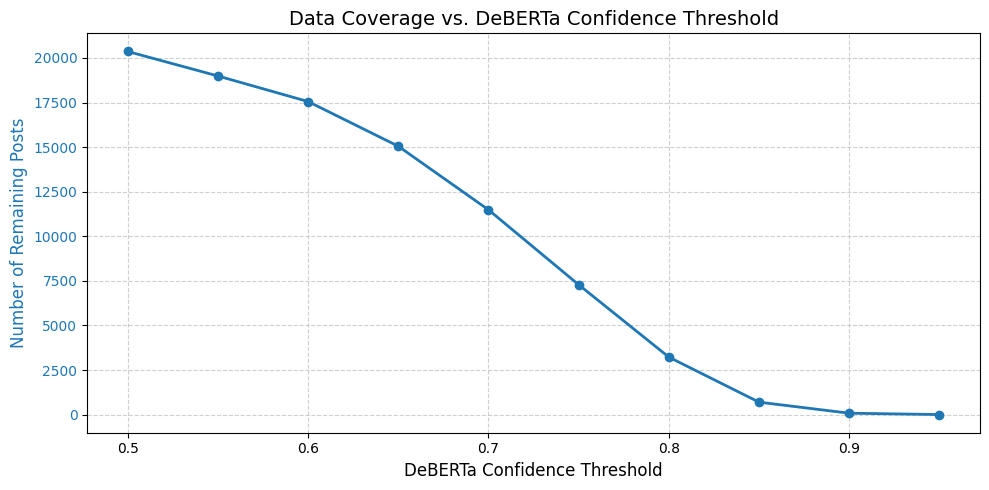

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def run_step_2a_graph_coverage_only():
    input_path = "/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_with_deberta.csv"
    print("load data...")
    df = pd.read_csv(input_path)

    # filter self talk posts
    df_eval = df[(df['is_self_talk'] == True) &
                 (df['gender_context'].isin(['female', 'male'])) &
                 (df['deberta_label'].notna())].copy()

    # check different thresholds
    thresholds = np.arange(0.5, 1.0, 0.05)
    results = []

    for t in thresholds:
        # filter posts by threshold
        df_filtered = df_eval[df_eval['deberta_score'] >= t]
        remaining_posts = len(df_filtered)
        results.append({'Threshold': t, 'Remaining_Posts': remaining_posts})

    df_results = pd.DataFrame(results)

    # plot graph
    fig, ax1 = plt.subplots(figsize=(10, 5))

    # num of posts
    color1 = 'tab:blue'
    ax1.set_xlabel('DeBERTa Confidence Threshold', fontsize=12)
    ax1.set_ylabel('Number of Remaining Posts', color=color1, fontsize=12)
    ax1.plot(df_results['Threshold'], df_results['Remaining_Posts'], color=color1, marker='o', linewidth=2)
    ax1.tick_params(axis='y', labelcolor=color1)

    # Adding a grid for readability
    ax1.grid(True, linestyle='--', alpha=0.6)

    plt.title('Data Coverage vs. DeBERTa Confidence Threshold', fontsize=14)
    fig.tight_layout()
    plt.show()

run_step_2a_graph_coverage_only()

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

def run_step_2b_confusion_matrix(chosen_threshold):
    input_path = "/content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_with_deberta.csv"
    df = pd.read_csv(input_path)

    df_eval = df[(df['is_self_talk'] == True) &
                 (df['gender_context'].isin(['female', 'male'])) &
                 (df['deberta_label'].notna())].copy()

    label_mapping = {
        'LABEL_0': 'female',
        'LABEL_1': 'male'
    }

    df_eval['deberta_label'] = df_eval['deberta_label'].map(label_mapping)

    df_eval['gender_context'] = df_eval['gender_context'].str.lower()
    df_eval['deberta_label'] = df_eval['deberta_label'].str.lower()

    # filter data by threshold
    df_chosen = df_eval[df_eval['deberta_score'] >= chosen_threshold]

    print("\n" + "="*50)
    print(f"--- statistics ({chosen_threshold}) ---")
    print("="*50)
    print(f"remaining posts: {len(df_chosen)}")
    print(f"correlation {(df_chosen['gender_context'] == df_chosen['deberta_label']).mean() * 100:.2f}%\n")

    print("Confusion Matrix (row: implicit labeling , col: DeBERTa):")
    labels = ['female', 'male']
    cm = confusion_matrix(df_chosen['gender_context'], df_chosen['deberta_label'], labels=labels)

    cm_df = pd.DataFrame(cm, index=['Old: Female', 'Old: Male'], columns=['Model: Female', 'Model: Male'])
    print(cm_df)

run_step_2b_confusion_matrix(chosen_threshold=0.75)


--- statistics (0.75) ---
remaining posts: 7285
correlation 34.29%

Confusion Matrix (row: implicit labeling , col: DeBERTa):
             Model: Female  Model: Male
Old: Female           2498            0
Old: Male             4787            0


#visualization


## Subreddits


In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/gdrive/MyDrive/Data mining/text mining/data/processed/labeled_all_gender_posts.csv")

# Keep only female and male contexts
df_filtered = df[df["gender_context"].isin(["female", "male"])]

# Group by subreddit and gender
grouped = (
    df_filtered
    .groupby(["subreddit", "gender_context"])
    .size()
    .unstack(fill_value=0)
)

# Ensure both columns exist
for col in ["female", "male"]:
    if col not in grouped.columns:
        grouped[col] = 0

# Rename columns
grouped = grouped.rename(columns={
    "female": "Female",
    "male": "Male"
})

# Add Total column per subreddit
grouped["Total"] = grouped["Female"] + grouped["Male"]

# Sort by total posts (optional)
grouped = grouped.sort_values(by="Total", ascending=False)

# ---- Add Grand Total Row ----
total_row = pd.DataFrame({
    "Female": [grouped["Female"].sum()],
    "Male": [grouped["Male"].sum()],
    "Total": [grouped["Total"].sum()]
}, index=["TOTAL"])

# Append total row
final_table = pd.concat([grouped, total_row])

# Print nicely formatted table
print("\nPosts per Subreddit by Gender Context:\n")
print(final_table.reset_index().to_string(index=False))



Posts per Subreddit by Gender Context:

                index  Female  Male  Total
                AIArt    2160  1997   4157
              ChatGPT    1768  2229   3997
    CSCareerQuestions    1357  2336   3693
           technology    1089  1742   2831
           Midjourney    1228  1136   2364
      StableDiffusion    1146   954   2100
ArtificialInteligence     589  1294   1883
          singularity     360  1077   1437
           artificial     420   922   1342
  cscareerquestionsEU     466   837   1303
             ClaudeAI     287   940   1227
      ExperiencedDevs     298   853   1151
              comfyui     422   657   1079
               OpenAI     310   724   1034
                 Bard     244   704    948
 learnmachinelearning     214   623    837
      MachineLearning     228   575    803
          datascience     231   567    798
           LocalLLaMA     206   580    786
                 bing     257   430    687
         deeplearning      65   568    633
          MLQ

Loading raw data from: /content/gdrive/MyDrive/Data mining/text mining/data/raw/all_gender_posts.txt...

RAW DATA SUMMARY
Total Posts Collected: 57392
Number of Subreddits:  33


/content/AI-Gender-Stereotypes/src/visualization/raw_EDA.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=sub_counts.index, y=sub_counts.values, palette="viridis")


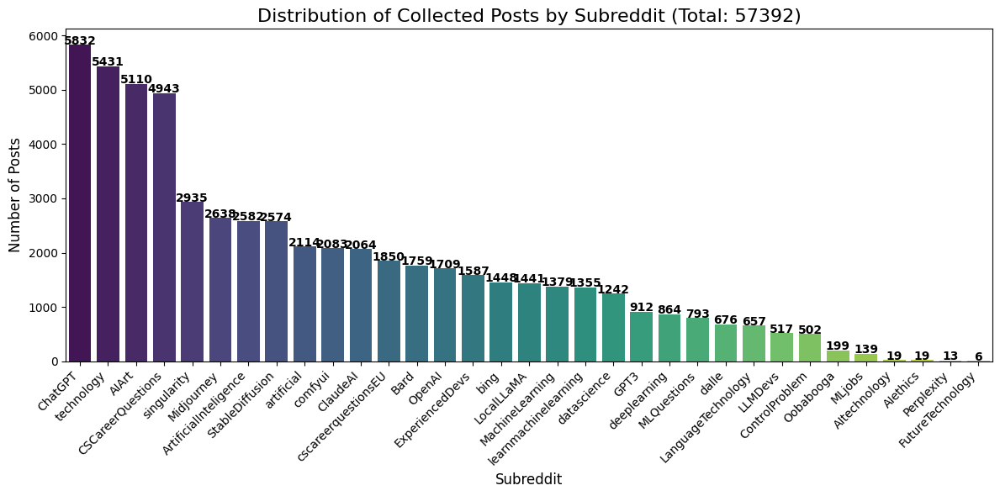


Generating Word Clouds per Subreddit...


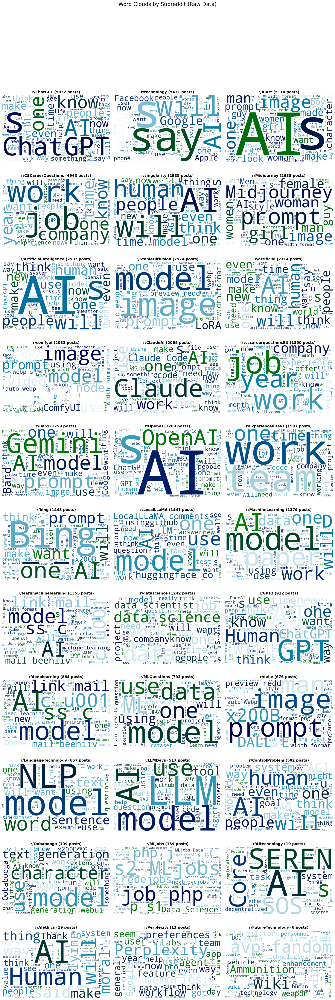

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import raw_EDA
import importlib

importlib.reload(raw_EDA)
raw_EDA.main()

##Data distribution

--- Loading Lexicons ---
Loaded 132 words from hard_ai.txt
Loaded 147 words from soft_ai.txt

STARTING POSTS ANALYSIS


/content/AI-Gender-Stereotypes/src/visualization/data_distribution.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df_clean, palette=PALETTE, order=valid_values)


Saved: Posts_Dist_Gender_Total.png


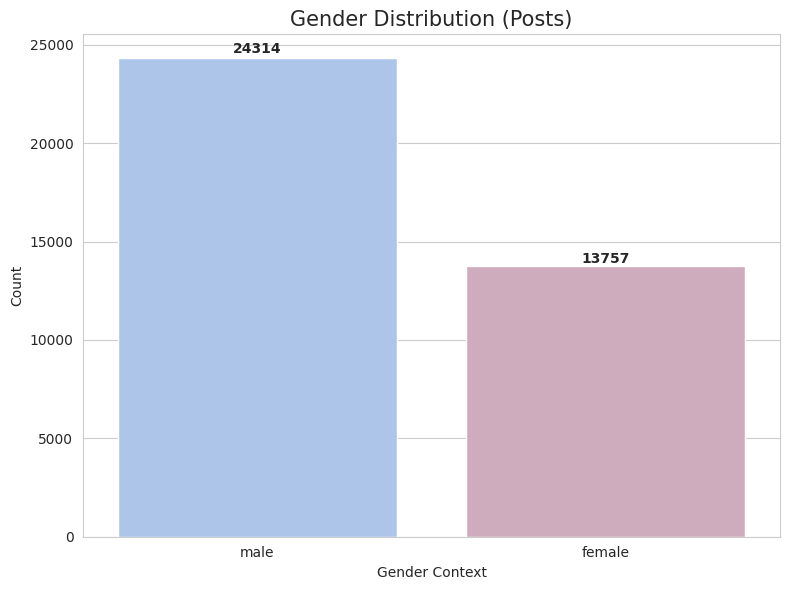

/content/AI-Gender-Stereotypes/src/visualization/data_distribution.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df_clean, palette=PALETTE, order=valid_values)


Saved: Posts_Dist_Category.png


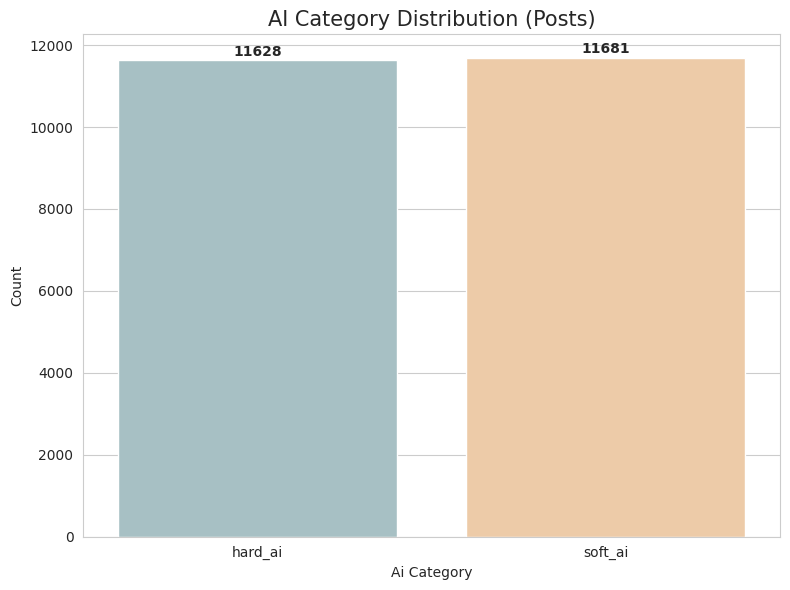

/content/AI-Gender-Stereotypes/src/visualization/data_distribution.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df_clean, palette=PALETTE, order=valid_values)


Saved: Posts_Dist_ResearchGroup.png


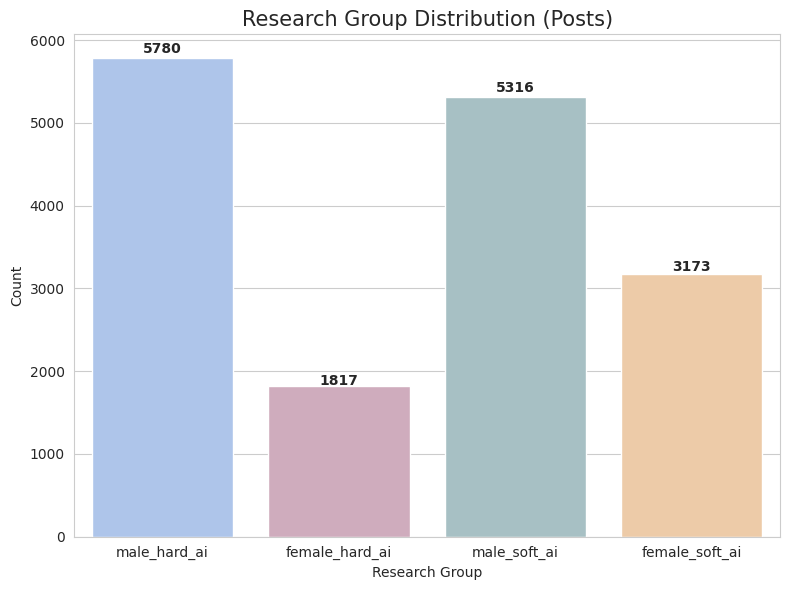

Saved: Posts_VADER_Dist.png


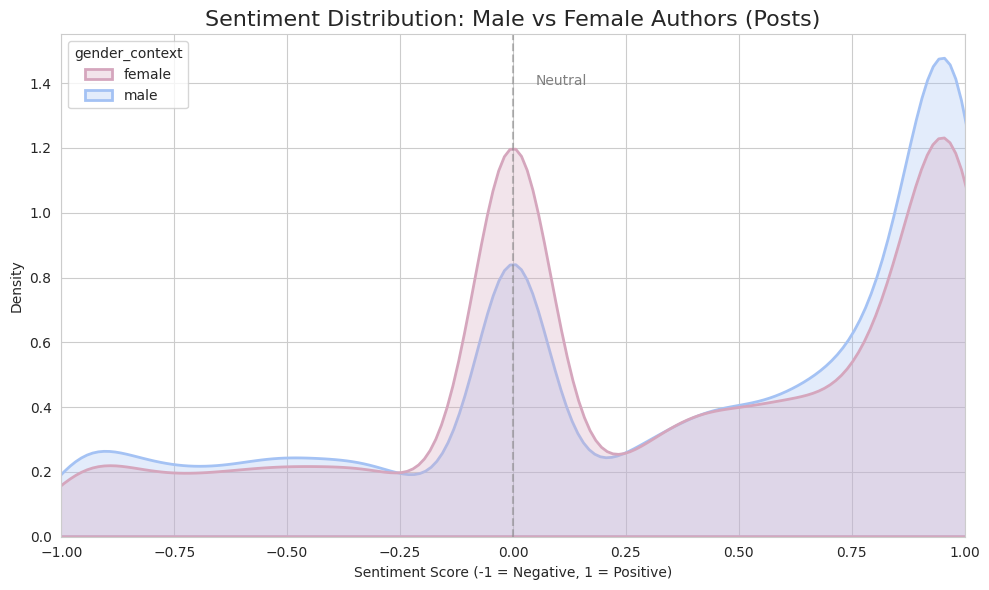

/content/AI-Gender-Stereotypes/src/visualization/data_distribution.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df_clean, palette=PALETTE, order=valid_values)


Saved: Posts_Dist_Gender_SelfTalk.png


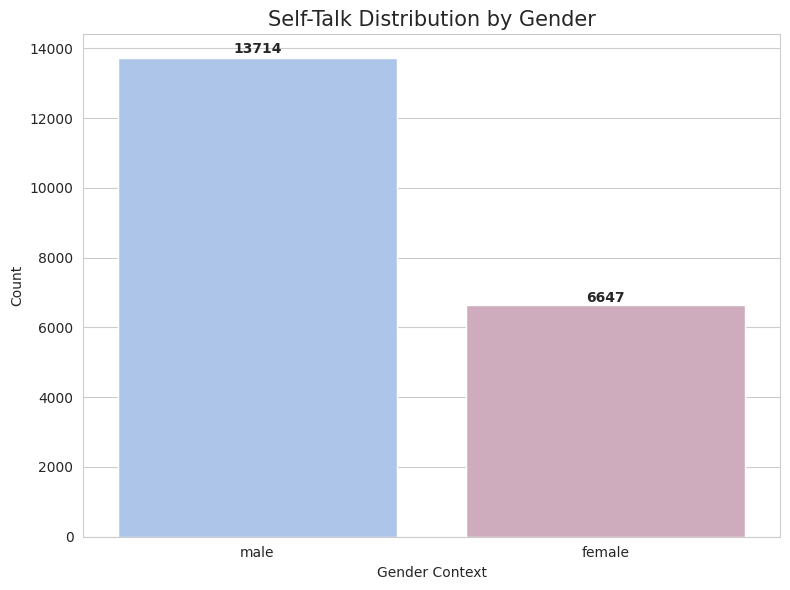


--- Running Lexicon-Specific Analysis ---
Generating Lexicon-Specific Word Clouds...
Saved: WordClouds_Lexicon_Specific.png


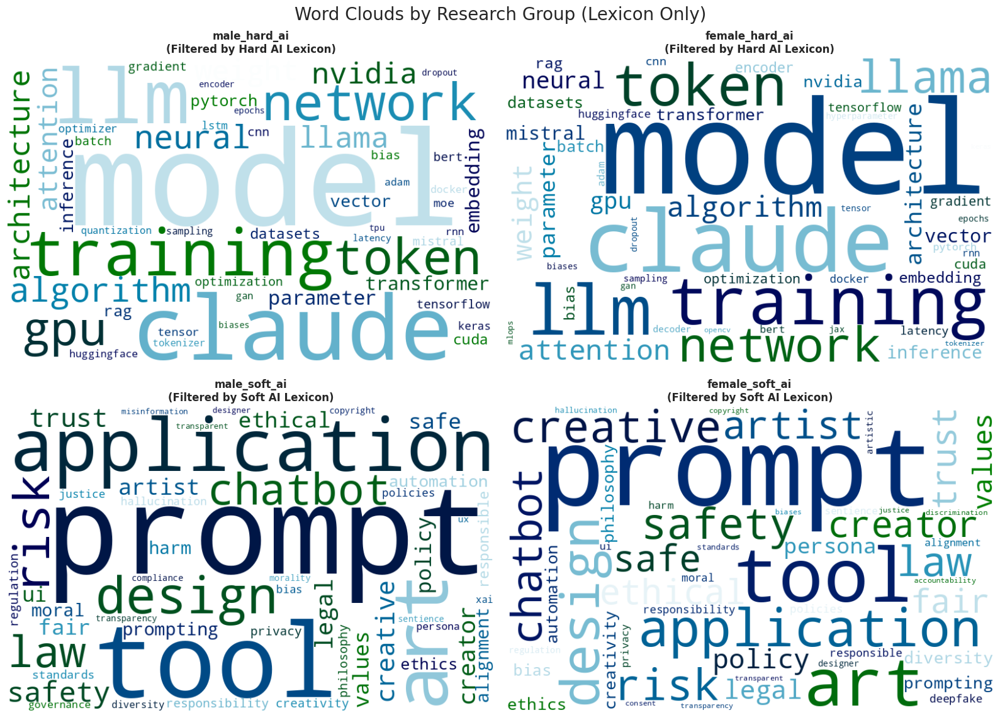

Generating Lexicon-Specific Top 10 Words...
Saved: Top_10_Words_Lexicon.png


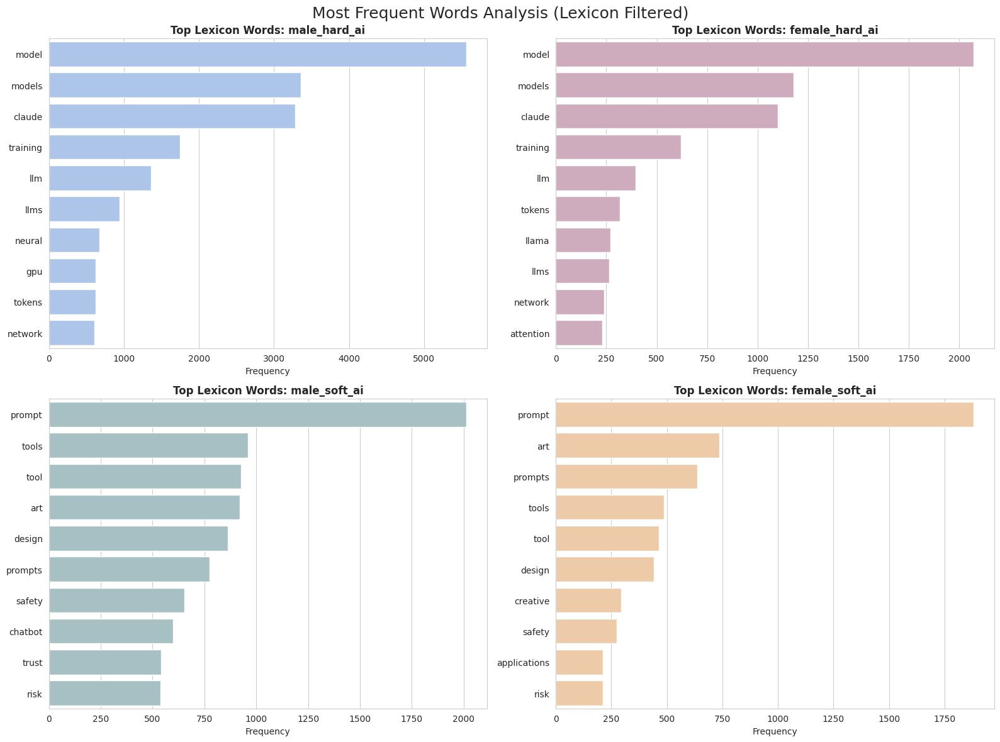


STARTING COMMENTS ANALYSIS


/content/AI-Gender-Stereotypes/src/visualization/data_distribution.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df_clean, palette=PALETTE, order=valid_values)


Saved: Comments_Dist_TargetGender.png


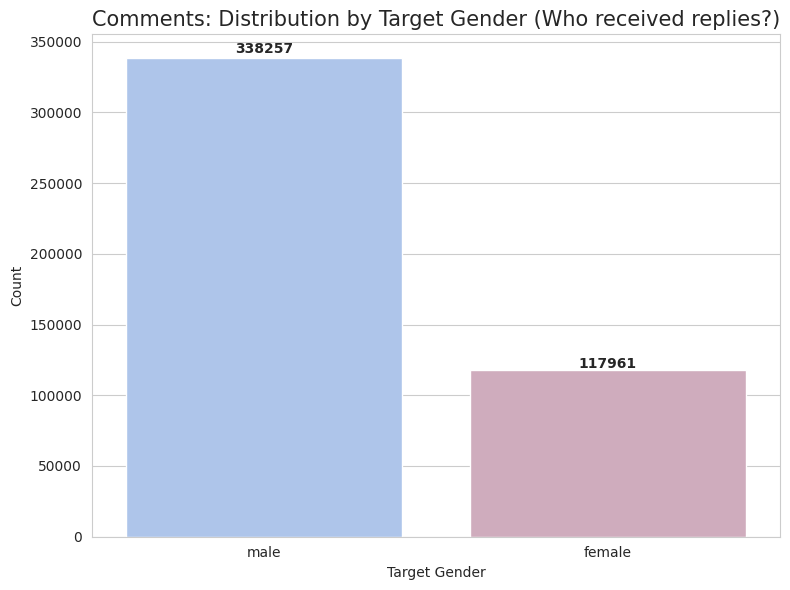

/content/AI-Gender-Stereotypes/src/visualization/data_distribution.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df_clean, palette=PALETTE, order=valid_values)


Saved: Comments_Dist_Category.png


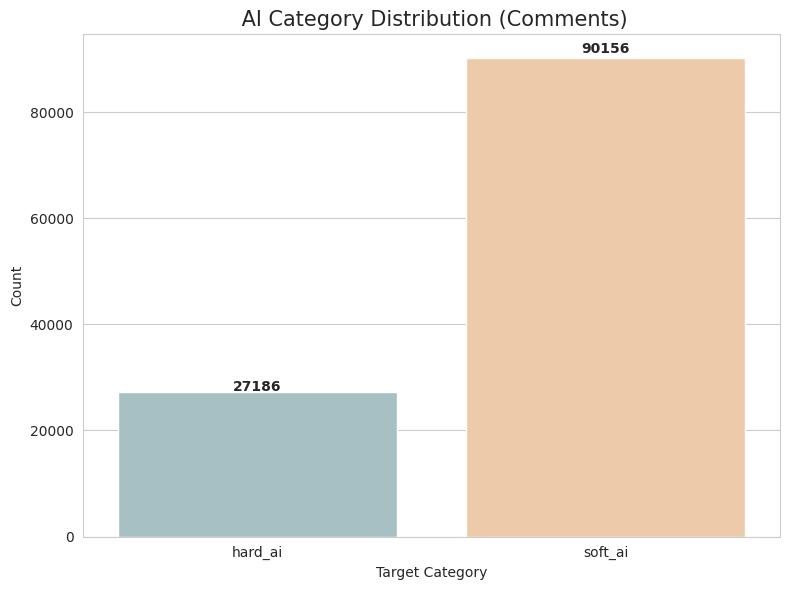

/content/AI-Gender-Stereotypes/src/visualization/data_distribution.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=col, data=df_clean, palette=PALETTE, order=valid_values)


Saved: Comments_Dist_ParentGroup.png


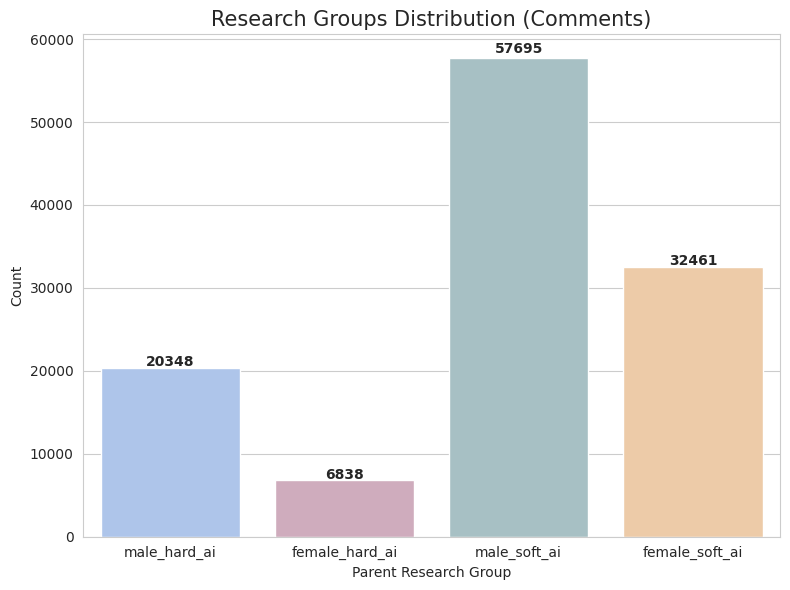

Saved: Comments_VADER_Dist.png


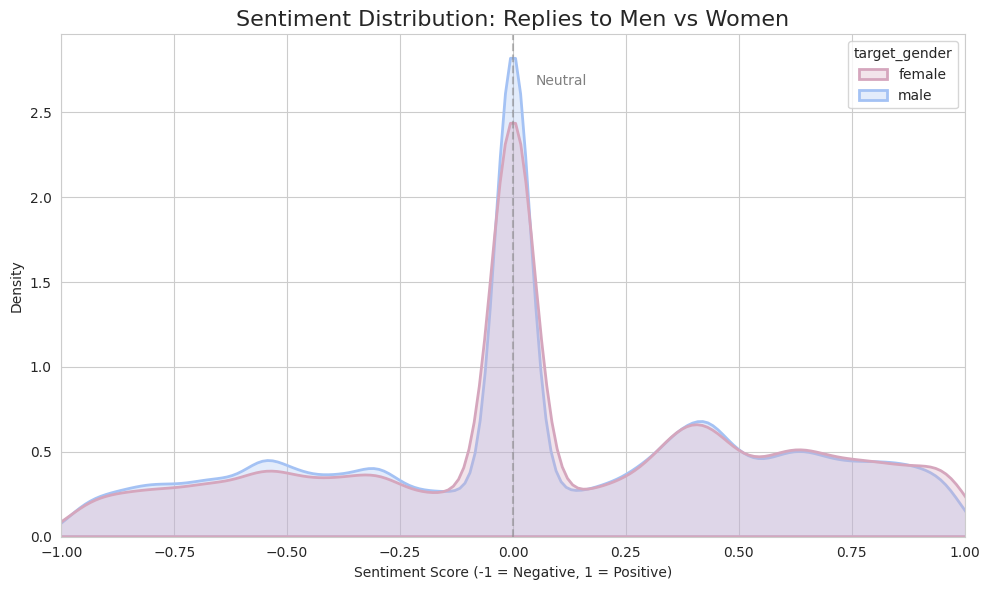


All visualizations completed.


In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import data_distribution
import importlib

importlib.reload(data_distribution)
data_distribution.main()


#Analysis

##First Q

H0: Gender and AI domain are independent variables, there is no significant difference in the frequency of Hard vs. Soft AI terms between female and male contexts.


H1: There is a statistically significant dependency between gender and AI domain.Women are mentioned more frequently with "Soft AI" words than men.


/content/AI-Gender-Stereotypes/src/analysis/statistical_analysis.py:37: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cell.set_text_props(weight='bold', color='white')


Generating Stacked Bar Chart...
Saved Stacked Bar Chart to: /content/gdrive/MyDrive/Data mining/text mining/visualization/RQ1_Stacked_Bar_Distribution.png


<Figure size 800x600 with 0 Axes>

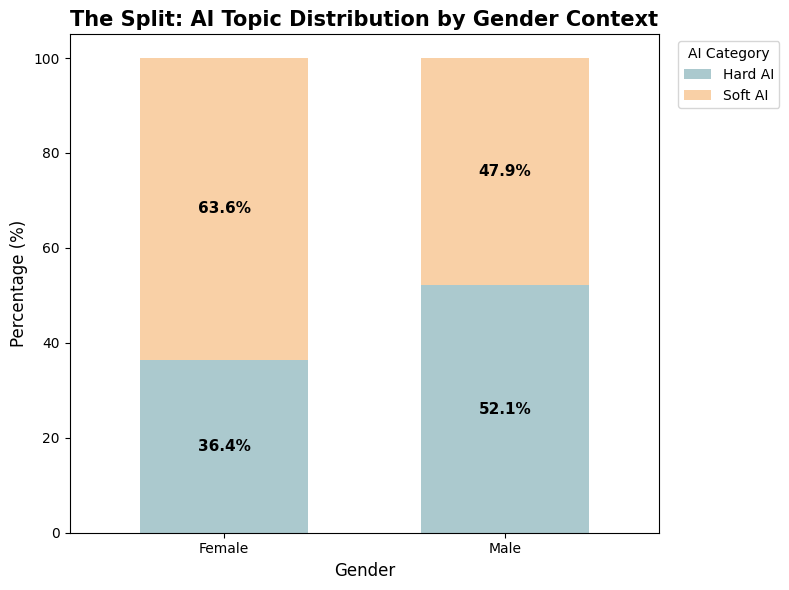

Chi-Square P-Value: 1.1421e-75

=> RESULT: SIGNIFICANT BIAS DETECTED.
There is a statistically significant dependency between Gender and AI Topic.


In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

import statistical_analysis
import importlib

importlib.reload(statistical_analysis)
statistical_analysis.main()

Chi-Square P-Value: 1.1421e-75

There is a statistically significant dependency between Gender and AI Topic.
(This proves that women and men appear in different frequencies across Hard vs Soft AI)

##Second Q

H0: There is no significant difference in the scores of dominance and confidence categories (specifically Power and Certainty) between women's and men's self-referential posts in AI contexts.

H1: Women's self-referential posts in AI contexts exhibit significantly lower scores in categories associated with dominance and confidence (specifically Power and Certainty) compared to men.


STARTING Sentiment Analysis (Original + Focused)
Loading comments dataset...
Total relevant comments (All Groups): 102175


/content/AI-Gender-Stereotypes/src/analysis/sentiment_analysis.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='parent_research_group', y='sentiment_vader', data=df_all,


Saved All-Groups Graph to: /content/gdrive/MyDrive/Data mining/text mining/visualization/RQ2_Sentiment_Boxplot_All.png


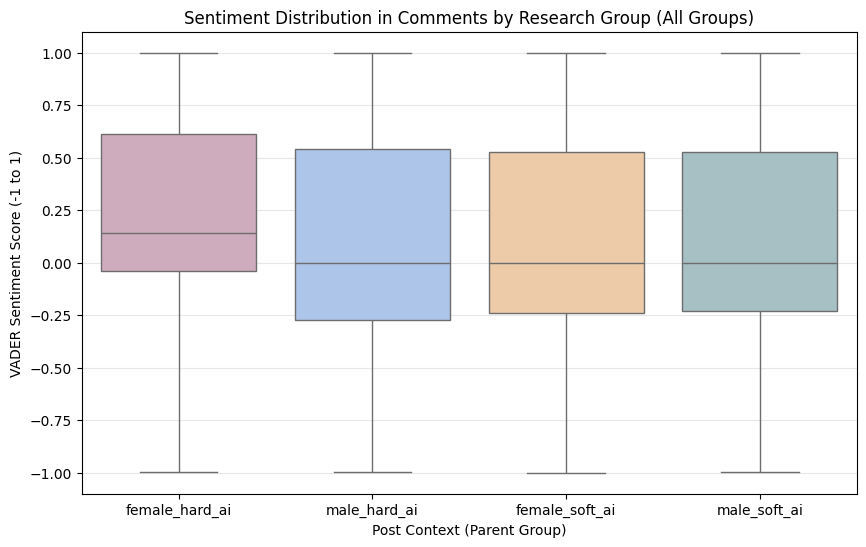

/content/AI-Gender-Stereotypes/src/analysis/sentiment_analysis.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='parent_research_group', y='sentiment_vader', data=df_hard,


Saved Focused Graph to: /content/gdrive/MyDrive/Data mining/text mining/visualization/RQ2_Sentiment_Boxplot_Focused.png


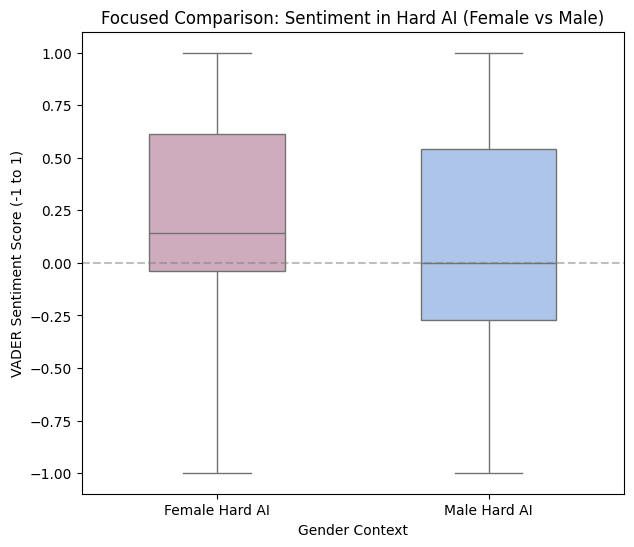


STATISTICAL TEST: Hostility in Hard AI (Female vs Male)
Female Hard AI (Mean): 0.1858
Male Hard AI   (Mean): 0.1091
Difference:            0.0767
------------------------------
T-Statistic: 10.5313
P-Value:     8.0925e-26

=> RESULT: SIGNIFICANT DIFFERENCE FOUND.
Women received significantly MORE POSITIVE (higher) sentiment than men (Surprisingly!).


In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

import sentiment_analysis
import importlib

importlib.reload(sentiment_analysis)
sentiment_analysis.main()

##Third Q

H0: There is no significant difference in the scores of dominance and confidence categories (specifically Power and Certainty) between women's and men's self-referential posts in AI contexts.

H1: Women's self-referential posts in AI contexts exhibit significantly lower scores in categories associated with dominance and confidence (specifically Power and Certainty) compared to men.


STARTING LIWC analysis
Loading posts dataset...
Total posts analyzing (Self-Talk only): 20361
Female posts: 6647
Male posts:   13714


/content/AI-Gender-Stereotypes/src/analysis/LIWC_analysis.py:98: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(


Saved Barplot to: /content/gdrive/MyDrive/Data mining/text mining/visualization/RQ3_LIWC_Barplot.png


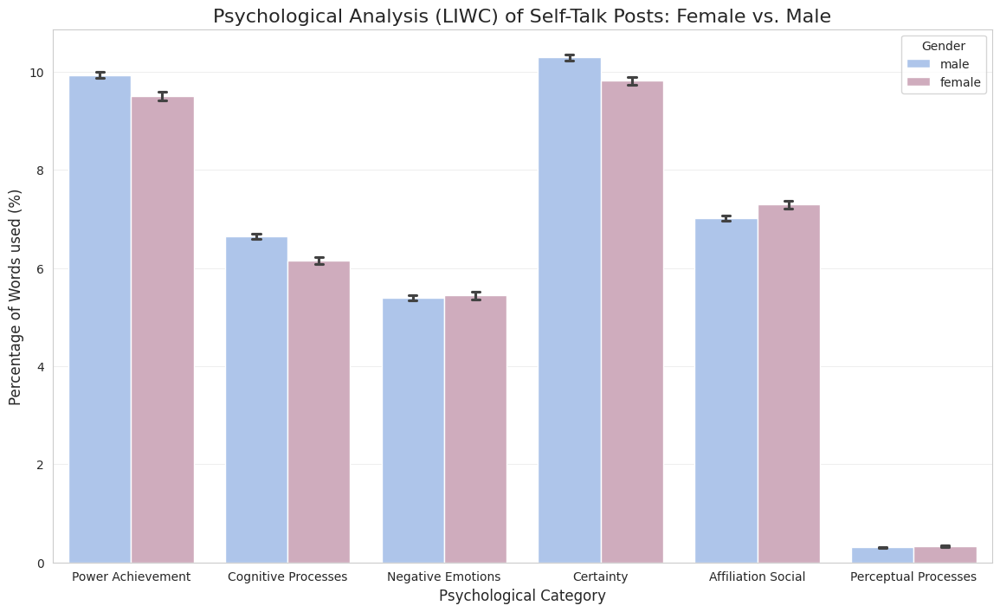


Calculating Statistics...
            Category Female Mean Male Mean  P-Value              Result
   Power Achievement      9.5041    9.9291 3.28e-16 Male > Female (SIG)
 Cognitive Processes      6.1496    6.6479 4.30e-31 Male > Female (SIG)
   Negative Emotions      5.4402    5.3910   0.2555             No Diff
           Certainty      9.8154   10.2895 3.62e-20 Male > Female (SIG)
  Affiliation Social      7.2937    7.0195 6.99e-09 Female > Male (SIG)
Perceptual Processes      0.3342    0.3058   0.0029 Female > Male (SIG)
Saved Stats Table to: /content/gdrive/MyDrive/Data mining/text mining/visualization/RQ3_LIWC_Stats_Table.png


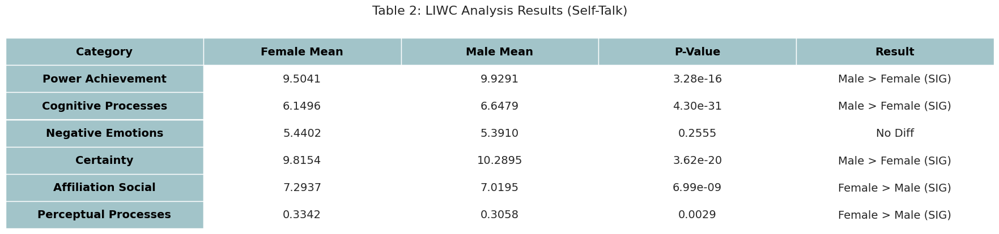

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

import LIWC_analysis
import importlib

importlib.reload(LIWC_analysis)
LIWC_analysis.main()

We analyzed posts where users talk about themselves ("I," "My") to understand how men and women present themselves in the AI community. The results show two very different styles:

**1. Men: The "Confident Expert" Style**
Data shows that men use a very specific type of language to establish authority:

* **High Certainty:** Men use words like *always, never,* and *absolutely* much more than women. They sound very sure of themselves (showing a "Confidence Gap").
* **Logic & Thinking:** Men use more words related to thinking processes (*think, analyze, because*). They feel the need to explain their logic and prove their knowledge.
* **Power & Success:** Men focus more on hierarchy and achievement (*win, control, superior*). They see the AI field as a competitive place.

**2. Women: The "Collaborative" Style**
Women use a different approach that focuses on connection:

* **Social & Teamwork:** Women use significantly more social words (*we, team, share, friend*).
* **Community Focus:** Instead of highlighting individual success ("I did this"), women tend to present their work as part of a group effort or a contribution to the community.

**3. Breaking the Stereotype: "Negative Emotions"**
This is the most surprising finding:

* There is **NO difference** in negative emotions between men and women.
* Contrary to the stereotype that women are "more emotional" or "fearful" of technology, the data proves that men and women express fear, anger, or sadness at the **exact same level**.

---

**In Short:**
While men focus on looking confident and proving their status, women focus on collaboration and teamwork. However, both genders struggle with the same amount of frustration and fear.

# Embedding

##Text Preprocessing

We need to clean the texts better than the first clean. We didnt clean before because VADER need the orginal text. Now for embedding we need better text preprocessing.


In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/preprocessing" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/preprocessing")

import full_cleaner
import importlib

importlib.reload(full_cleaner)
full_cleaner.main()

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!



--- Processing POSTS ---
Loading data from /content/gdrive/MyDrive/Data mining/text mining/data/processed/final_posts_dataset.csv...
Detected POSTS dataset. Merging title + selftext...

--- Deduplication Report ---
Original size: 57392
Duplicates removed: 1043
Clean size: 56349
----------------------------

Starting preprocessing pipeline (tokenization, cleaning, lemmatization)...
Removed 82 empty rows after cleaning.
Saving processed data (Pickle) to /content/gdrive/MyDrive/Data mining/text mining/data/processed/word2vec_posts.pkl...
Done!

--- Processing COMMENTS ---
Loading data from /content/gdrive/MyDrive/Data mining/text mining/data/processed/final_comments_dataset.csv...
Detected COMMENTS dataset. Using 'body' column...

--- Deduplication Report ---
Original size: 942108
Duplicates removed: 106790
Clean size: 835318
----------------------------

Starting preprocessing pipeline (tokenization, cleaning, lemmatization)...
Removed 3110 empty rows after cleaning.
Saving processed da

## Word2Vec Embeddings

For embedding we want all the data- posts and comments combined.

###First model

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

import embeddings
import importlib

importlib.reload(embeddings)
embeddings.main()

Loading preprocessed datasets...
Loaded 56267 posts.
Loaded 832208 comments.
Total sentences for training: 888475
Training Word2Vec model...
Params: Size=100, Window=5, MinCount=5, Epochs=15
Saving model to /content/gdrive/MyDrive/Data mining/text mining/data/processed/gender_ai_w2v.model...
Done! Vocabulary size: 55147 unique words.

      PHASE 2: FULL SEMANTIC ANALYSIS      
Lexicon Coverage (Found in Model):
 - Hard AI: 85 / 132
 - Soft AI: 95 / 148

--- A. Quantitative: Cosine Distance Analysis ---
[Female Group]
   Dist to Hard AI: 0.2174
   Dist to Soft AI: 0.3621
   => Result: Closer to SOFT AI (Gap: 0.1447)
------------------------------
[Male Group]
   Dist to Hard AI: 0.2768
   Dist to Soft AI: 0.3860
   => Result: Closer to SOFT AI (Gap: 0.1092)
------------------------------

--- B. Qualitative: Most Similar Words (Context) ---
Closest to 'woman': ['women', 'man', 'men', 'red-haired', 'male']
Closest to 'man': ['dude', 'guy', 'woman', 'dudette', 'reeeeeeee']
Closest to 'fe

###Training a better model

In [ ]:
import pandas as pd
import numpy as np
import os

BASE_DIR = "/content/gdrive/MyDrive/Data mining/text mining/data"
POSTS_PKL = os.path.join(BASE_DIR, "processed/word2vec_posts.pkl")
COMMENTS_PKL = os.path.join(BASE_DIR, "processed/word2vec_comments.pkl")

all_texts_lengths = []

print("Loading data for statistics...")

# posts
if os.path.exists(POSTS_PKL):
    df_posts = pd.read_pickle(POSTS_PKL)
    posts_lengths = df_posts['cleaned_tokens'].apply(len).tolist()
    all_texts_lengths.extend(posts_lengths)
    print(f"Added {len(posts_lengths)} posts.")

# comments
if os.path.exists(COMMENTS_PKL):
    df_comments = pd.read_pickle(COMMENTS_PKL)
    comments_lengths = df_comments['cleaned_tokens'].apply(len).tolist()
    all_texts_lengths.extend(comments_lengths)
    print(f"Added {len(comments_lengths)} comments.")

# Statistics
if all_texts_lengths:
    print(f"\n--- Text Length Statistics (Number of Tokens) ---")
    print(f"Total documents: {len(all_texts_lengths)}")
    print(f"Average length: {np.mean(all_texts_lengths):.1f}")
    print(f"Median length: {np.median(all_texts_lengths):.1f}")
    print(f"90th percentile: {np.percentile(all_texts_lengths, 90):.1f}")
    print(f"95th percentile: {np.percentile(all_texts_lengths, 95):.1f}")
    print(f"Max length: {np.max(all_texts_lengths)}")

    print("\n--- Insight for Hyperparameters ---")
    avg_len = np.mean(all_texts_lengths)
    if avg_len > 20:
        print(f"High average length ({avg_len:.1f}) supports increasing Context Window (e.g., from 5 to 10).")
    else:
        print(f"Short average length ({avg_len:.1f}) suggests keeping a smaller Context Window.")
else:
    print("No data found to analyze.")

Loading data for statistics...
Added 56267 posts.
Added 832208 comments.

--- Text Length Statistics (Number of Tokens) ---
Total documents: 888475
Average length: 20.7
Median length: 10.0
90th percentile: 43.0
95th percentile: 68.0
Max length: 3645

--- Insight for Hyperparameters ---
High average length (20.7) supports increasing Context Window (e.g., from 5 to 10).


we changed the parameters to bigger vector and context window.

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

import word2vec_embedding
import importlib

importlib.reload(word2vec_embedding)
word2vec_embedding.main()

Loading preprocessed datasets...
Loaded 56267 posts.
Loaded 832208 comments.
Total sentences for training: 888475
Training Word2Vec model...
Params: Size=300, Window=10, MinCount=10, Epochs=30
Saving model to /content/gdrive/MyDrive/Data mining/text mining/models/gender_ai_w2v_optimized.model...
Done! Vocabulary size: 36054 unique words.

Lexicon Coverage check:
 - Hard AI: 85 found / 132 total
 - Soft AI: 94 found / 148 total

--- A. Quantitative: Group Cosine Distance Analysis ---

[Female Group Average]
   Similarity to Hard AI: 0.2014
   Similarity to Soft AI: 0.3499
   => Closer to: SOFT (Gap: 0.1485)

[Male Group Average]
   Similarity to Hard AI: 0.2742
   Similarity to Soft AI: 0.3429
   => Closer to: SOFT (Gap: 0.0687)

[Direct Comparison: Who is closer to Hard AI?]
   RESULT: MEN are closer to Hard AI by 0.0728

[Direct Comparison: Who is closer to Soft AI?]
   RESULT: WOMEN are closer to Soft AI by 0.0070

--- Specific Requirement: 'Woman' vs 'Man' Analysis ---
['woman']
   

We see decrease in word count (unique words the model learned). it is a direct and intentional result of the change in parameters, and it makes the model more accurate and less "noisy" (Quality vs. Quantity)

But in both models male is closer to hard AI compare to female.

##Visualization

###word2vec model

Loading model from /content/gdrive/MyDrive/Data mining/text mining/data/processed/gender_ai_w2v.model...
Loading lexicons...
Using FILTERED gender lists...
Words to plot: Hard=85, Soft=95, Female=9, Male=9
Total points: 198
Running t-SNE dimensionality reduction...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Generating plot...


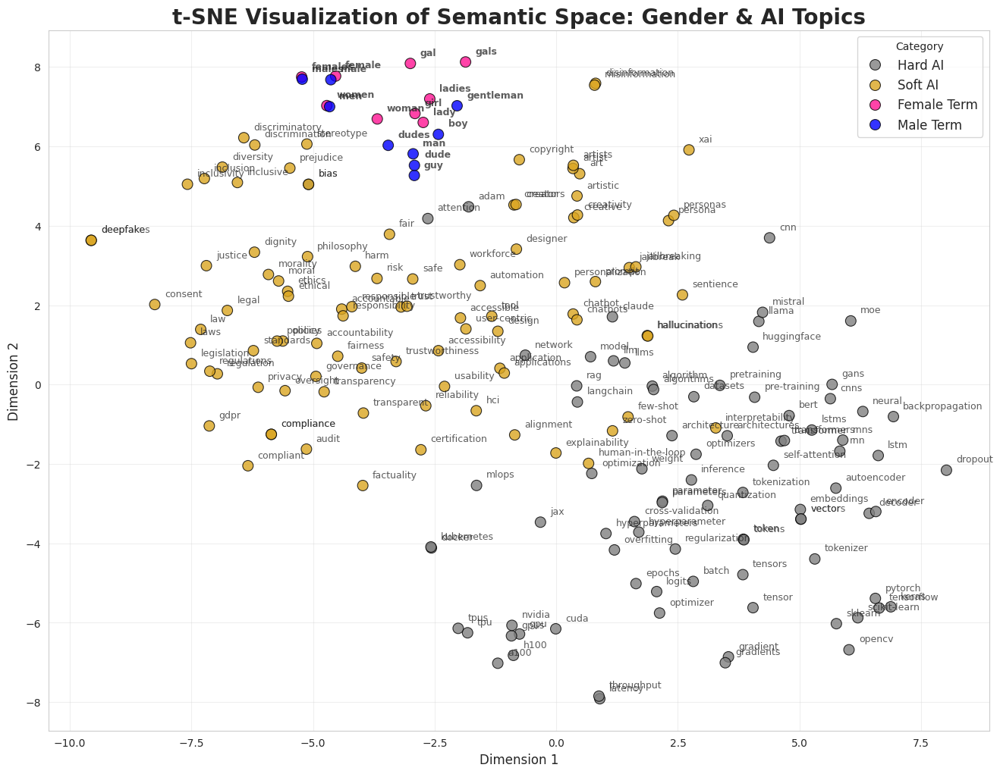


--- Starting PCA Visualization ---
Running PCA dimensionality reduction...
PCA Explained Variance Ratio: [0.13884431 0.05949382] (Total: 0.20)


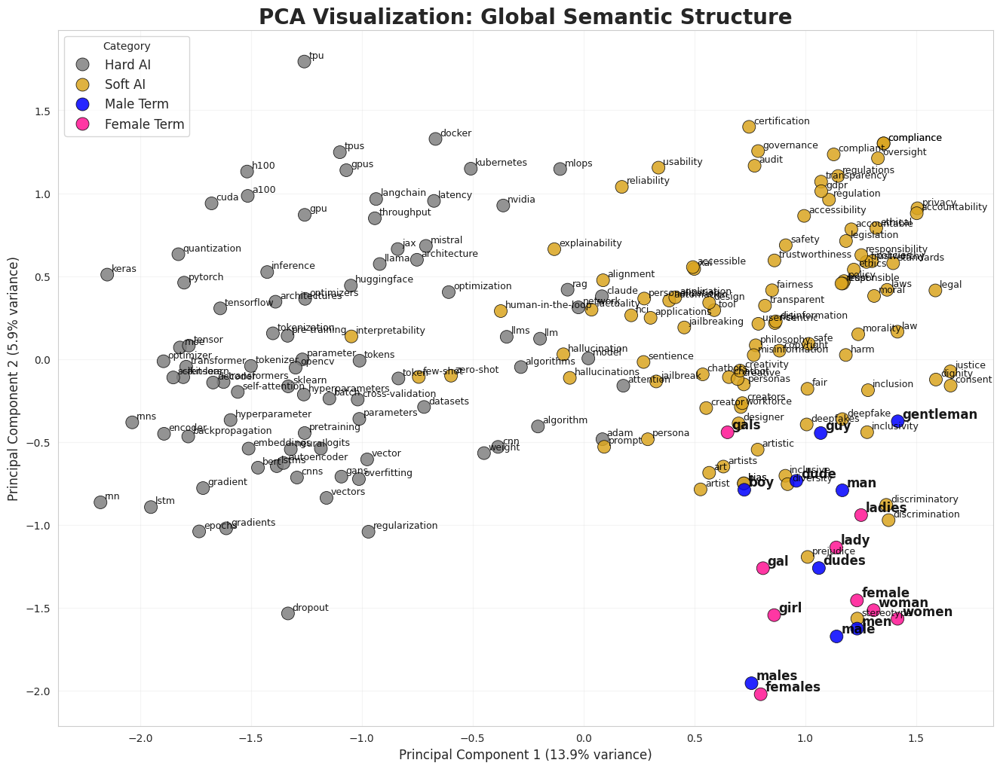

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import embedding_visualization
import importlib

importlib.reload(embedding_visualization)
embedding_visualization.main()

###Improved word2vec model

#### T-SNE

Loading OPTIMIZED model from /content/gdrive/MyDrive/Data mining/text mining/models/gender_ai_w2v_optimized.model...
Loading full lexicons...
Total words to plot: 197
 - Hard AI: 85
 - Soft AI: 94
Running t-SNE dimensionality reduction...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Generating plot...
Optimizing text placement (this might take a few seconds)...


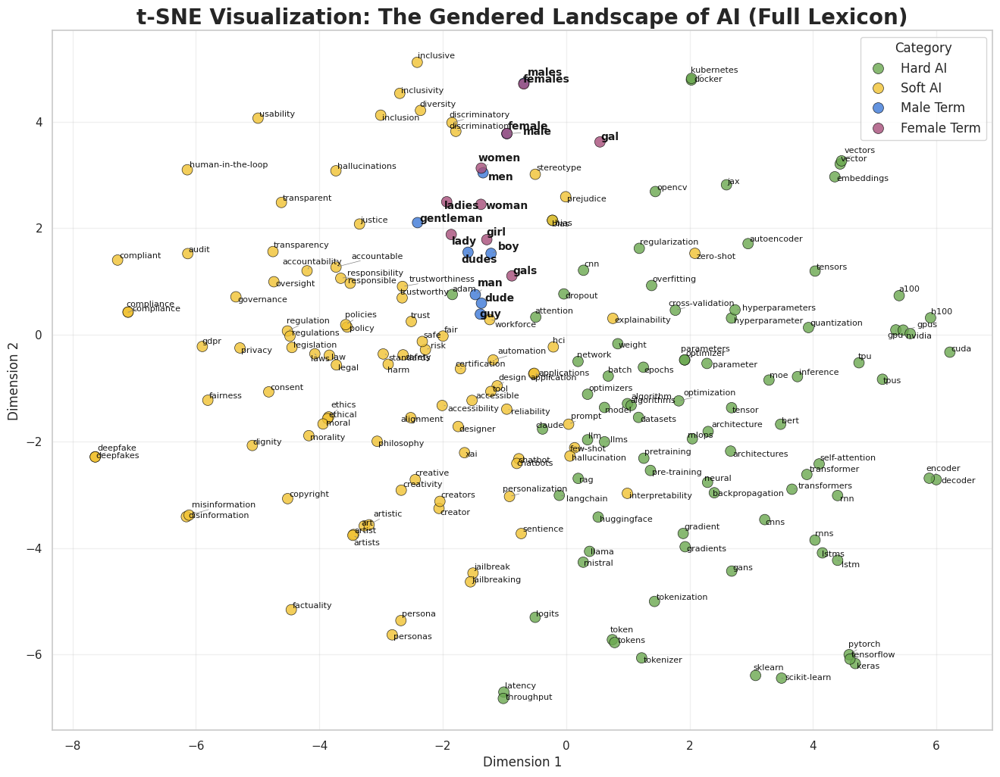

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import improved_embedding_visualization
import importlib

importlib.reload(improved_embedding_visualization)
improved_embedding_visualization.main()

T-SNE with all the words

Loading model from /content/gdrive/MyDrive/Data mining/text mining/models/gender_ai_w2v_optimized.model...
Loading full lexicons from files...

--- Plotting Configuration ---
Target Words (Highlighted): 208
 - Hard AI: 85
 - Soft AI: 94
 - Male Terms: 14
 - Female Terms: 17
Background Words (Gray): 35846
------------------------------
Running t-SNE on full vocabulary (Pro+ Mode)...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Rendering plot...


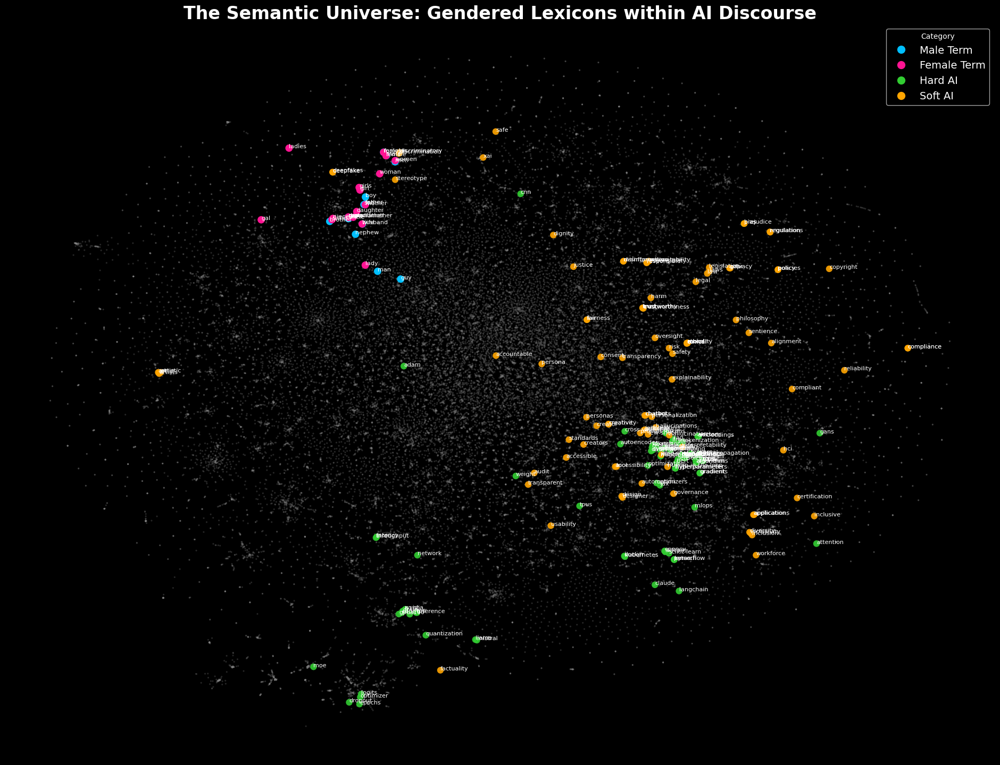

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import full_tsne
import importlib

importlib.reload(full_tsne)
full_tsne.main()

#### More visualizations

Loading model...


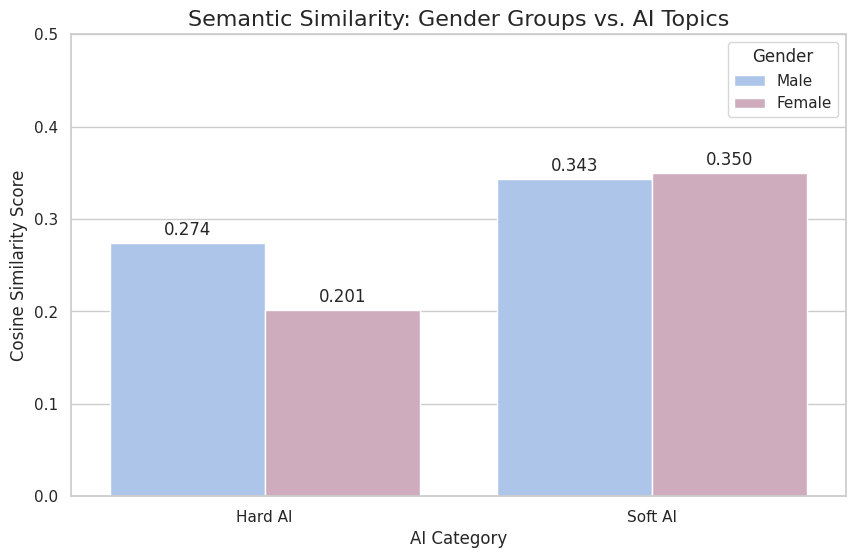

/tmp/ipython-input-768400293.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x='score', y='word', palette=colors)


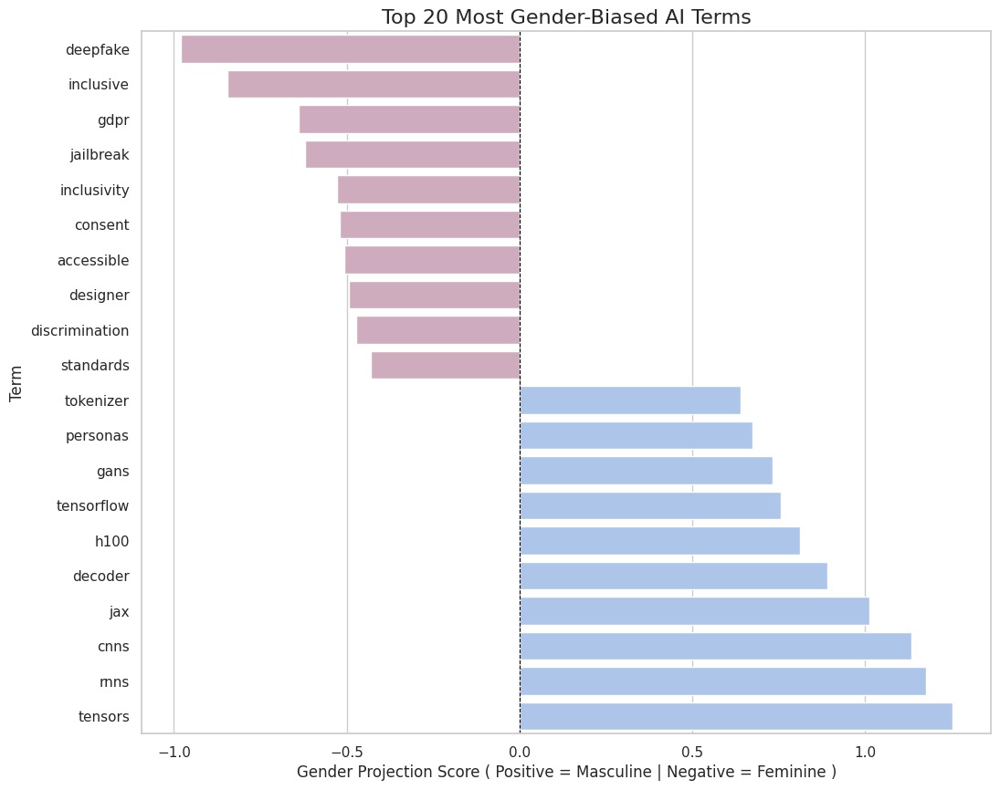

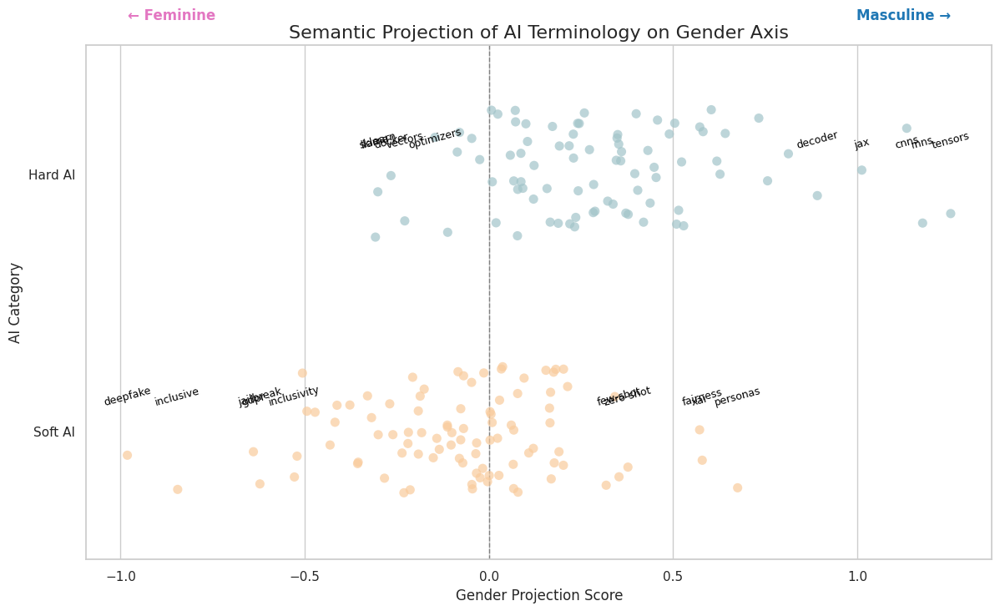

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from gensim.models import Word2Vec
import os
import sys

if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

from word2vec_embedding import load_lexicon, get_avg_vector

#routes
BASE_DIR = "/content/gdrive/MyDrive/Data mining/text mining/data"
MODEL_PATH = "/content/gdrive/MyDrive/Data mining/text mining/models/gender_ai_w2v_optimized.model"

# load model
print("Loading model...")
model = Word2Vec.load(MODEL_PATH)

# load lexicons
hard_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/hard_ai.txt"))
soft_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/soft_ai.txt"))
female_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/gender_female.txt"))
male_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/gender_male.txt"))

# ==========================================
# The Gap Analysis
# ==========================================
def plot_gap_analysis():
    # calculate avg vectors
    hard_vec = get_avg_vector(model, hard_words)
    soft_vec = get_avg_vector(model, soft_words)
    female_vec = get_avg_vector(model, female_words)
    male_vec = get_avg_vector(model, male_words)

    # calculate similarity
    sim_data = {
        'Gender': ['Male', 'Male', 'Female', 'Female'],
        'AI Type': ['Hard AI', 'Soft AI', 'Hard AI', 'Soft AI'],
        'Similarity': [
            model.wv.cosine_similarities(male_vec, [hard_vec])[0],
            model.wv.cosine_similarities(male_vec, [soft_vec])[0],
            model.wv.cosine_similarities(female_vec, [hard_vec])[0],
            model.wv.cosine_similarities(female_vec, [soft_vec])[0]
        ]
    }

    df_sim = pd.DataFrame(sim_data)

    # graph plotting
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")

    ax = sns.barplot(data=df_sim, x='AI Type', y='Similarity', hue='Gender',
                     palette={'Male': '#a4c2f4', 'Female': '#d5a6bd'})

    plt.title('Semantic Similarity: Gender Groups vs. AI Topics', fontsize=16)
    plt.ylabel('Cosine Similarity Score', fontsize=12)
    plt.xlabel('AI Category', fontsize=12)
    plt.ylim(0, 0.5)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3)

    plt.show()

# ==========================================
# Top 10 Most Gendered Terms (Bias Leaderboard)
# ==========================================
def plot_bias_leaderboard():
    # create gender vector
    male_vec = get_avg_vector(model, male_words)
    female_vec = get_avg_vector(model, female_words)
    gender_axis = male_vec - female_vec

    def get_score(word):
        return np.dot(model.wv[word], gender_axis)

    all_ai_words = list(set(hard_words + soft_words))
    word_scores = []

    for w in all_ai_words:
        if w in model.wv:
            score = get_score(w)
            cat = 'Hard AI' if w in hard_words else 'Soft AI'
            word_scores.append({'word': w, 'score': score, 'category': cat})

    df_scores = pd.DataFrame(word_scores)

    top_male = df_scores.nlargest(10, 'score')
    top_female = df_scores.nsmallest(10, 'score')

    df_plot = pd.concat([top_male, top_female]).sort_values('score')
    plt.figure(figsize=(12, 10))

    # male-negative, female-positive
    colors = ['#a4c2f4' if x > 0 else '#d5a6bd' for x in df_plot['score']]
    sns.barplot(data=df_plot, x='score', y='word', palette=colors)

    plt.title('Top 20 Most Gender-Biased AI Terms', fontsize=16)
    plt.xlabel('Gender Projection Score ( Positive = Masculine | Negative = Feminine )', fontsize=12)
    plt.ylabel('Term', fontsize=12)

    plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
    plt.show()


# ==========================================
# Word Projection / Scatter Plot
# ==========================================
def plot_gender_axis_scatter():
    # calculate gender vector
    male_vec = get_avg_vector(model, male_words)
    female_vec = get_avg_vector(model, female_words)
    gender_direction = male_vec - female_vec

    data = []

    # Hard AI
    for w in hard_words:
        if w in model.wv:
            score = np.dot(model.wv[w], gender_direction)
            data.append({'word': w, 'score': score, 'category': 'Hard AI'})

    # Soft AI
    for w in soft_words:
        if w in model.wv:
            score = np.dot(model.wv[w], gender_direction)
            data.append({'word': w, 'score': score, 'category': 'Soft AI'})

    df_plot = pd.DataFrame(data)

    # plot graph
    plt.figure(figsize=(14, 8))
    sns.set_theme(style="whitegrid")

    ax = sns.stripplot(data=df_plot, x='score', y='category', hue='category',
                       palette={'Hard AI': '#a2c4c9', 'Soft AI': '#f9cb9c'},
                       size=8, alpha=0.7, jitter=0.25)

    plt.axvline(0, color='grey', linestyle='--', linewidth=1)

    plt.text(df_plot['score'].max(), -0.6, 'Masculine →', fontsize=12, color='#1f77b4', ha='right', fontweight='bold')
    plt.text(df_plot['score'].min(), -0.6, '← Feminine', fontsize=12, color='#e377c2', ha='left', fontweight='bold')

    texts_to_add = []

    for category in ['Hard AI', 'Soft AI']:
        subset = df_plot[df_plot['category'] == category]

        # top 5 Masculine/Feminine words
        extremes = pd.concat([subset.nlargest(5, 'score'), subset.nsmallest(5, 'score')])

        # 0-Hard, 1- Soft
        y_pos = 0 if category == 'Hard AI' else 1

        for _, row in extremes.iterrows():
            plt.text(row['score'], y_pos - 0.1, row['word'],
                     fontsize=9, color='black', ha='center', rotation=15)

    plt.title('Semantic Projection of AI Terminology on Gender Axis', fontsize=16)
    plt.xlabel('Gender Projection Score', fontsize=12)
    plt.ylabel('AI Category', fontsize=12)

    if ax.legend_:
        ax.legend_.remove()

    plt.show()

plot_gap_analysis()
plot_bias_leaderboard()
plot_gender_axis_scatter()

Analogy

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from gensim.models import Word2Vec
import os
import sys
if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

from word2vec_embedding import load_lexicon, get_avg_vector

#routes
BASE_DIR = "/content/gdrive/MyDrive/Data mining/text mining/data"
MODEL_PATH = "/content/gdrive/MyDrive/Data mining/text mining/models/gender_ai_w2v_optimized.model"

# load model
print("Loading model...")
model = Word2Vec.load(MODEL_PATH)

# load lexicons
hard_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/hard_ai.txt"))
soft_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/soft_ai.txt"))
female_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/gender_female.txt"))
male_words = load_lexicon(os.path.join(BASE_DIR, "lexicons/gender_male.txt"))

def solve_analogy(model, word_a, word_b, word_c):
    """
    Solves: A is to B as C is to ?
    Formula: B - A + C = ?
    Example: Man (A) is to Programmer (B) as Woman (C) is to...
    """
    try:
        # positive = B + C, negative = A
        result = model.wv.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)
        print(f"'{word_a}' : '{word_b}' :: '{word_c}' : '{result[0][0]}' (Score: {result[0][1]:.2f})")
    except KeyError as e:
        print(f"Error: One of the words is not in the vocabulary: {e}")

print("--- AI Gender Analogies Test (Based on Leaderboard) ---")

# Man : Tensors :: Woman : ?
print("\nTest 1: The Core Math (Tensors)")
solve_analogy(model, 'man', 'tensors', 'woman')

# Man : CNNs :: Woman : ?
print("\nTest 2: Architecture (CNNs)")
solve_analogy(model, 'man', 'cnns', 'woman')

# Man : H100 :: Woman : ?
print("\nTest 3: Hardware (H100)")
solve_analogy(model, 'man', 'h100', 'woman')

# Man : Tensorflow :: Woman : ?
print("\nTest 4: Framework (Tensorflow)")
solve_analogy(model, 'man', 'tensorflow', 'woman')

# Man : Performance :: Woman : ?
print("\nTest 5: Values (Performance)")
solve_analogy(model, 'man', 'performance', 'woman')

# Man : transformer :: Woman : ?
print("\nTest 5: Values (Performance)")
solve_analogy(model, 'man', 'transformer', 'woman')

Loading model...
--- AI Gender Analogies Test (Based on Leaderboard) ---

Test 1: The Core Math (Tensors)
'man' : 'tensors' :: 'woman' : 'ffn' (Score: 0.38)

Test 2: Architecture (CNNs)
'man' : 'cnns' :: 'woman' : 'dnns' (Score: 0.37)

Test 3: Hardware (H100)
'man' : 'h100' :: 'woman' : 'nvidia' (Score: 0.42)

Test 4: Framework (Tensorflow)
'man' : 'tensorflow' :: 'woman' : 'keras' (Score: 0.53)

Test 5: Values (Performance)
'man' : 'performance' :: 'woman' : 'metrics' (Score: 0.38)

Test 5: Values (Performance)
'man' : 'transformer' :: 'woman' : 'transformers' (Score: 0.40)


We dont see here big difference between the genders. more like synonyms.. need to think of better analogies.

Loading model from /content/gdrive/MyDrive/Data mining/text mining/data/../models/gender_ai_w2v_optimized.model...
Fitting PCA on global vocabulary space...
Plot saved to /content/gdrive/MyDrive/Data mining/text mining/data/../models/vector_arrows_plot.png


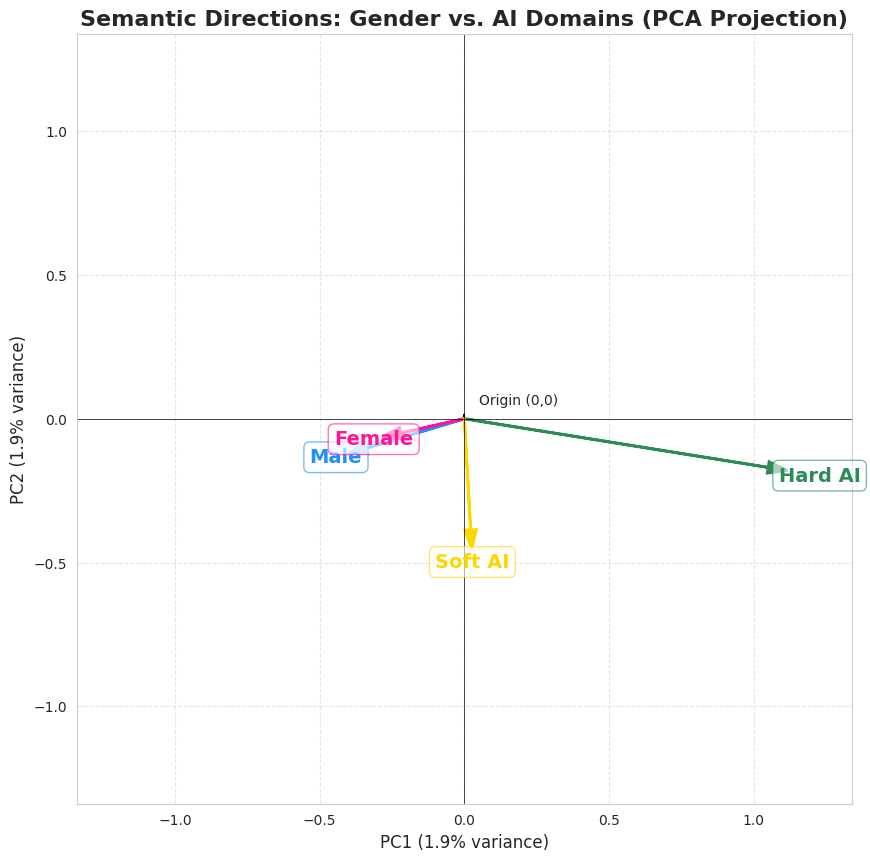

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
import os

sns.set_style("whitegrid")

COLORS = {
    'Male': '#1E90FF',
    'Female': '#FF1493',
    'Hard AI': '#2E8B57',
    'Soft AI': '#FFD700'
}

#filtered gender lexicons
FILTERED_MALE = ['man', 'male', 'boy', 'he', 'him', 'his', 'men', 'males', 'guy', 'guys']
FILTERED_FEMALE = ['woman', 'female', 'girl', 'she', 'her', 'hers', 'women', 'females', 'lady']

def load_lexicon(path):
    if not os.path.exists(path): return []
    with open(path, 'r', encoding='utf-8') as f:
        return [line.strip().lower() for line in f if line.strip()]

def get_avg_vector(model, words):
    valid_words = [w for w in words if w in model.wv]
    if not valid_words:
        return np.zeros(model.vector_size)
    return np.mean(model.wv[valid_words], axis=0)

def visualize_arrows(model_path, hard_lex_path, soft_lex_path):
    print(f"Loading model from {model_path}...")
    model = Word2Vec.load(model_path)

    # load ai lexicons
    hard_words = load_lexicon(hard_lex_path)
    soft_words = load_lexicon(soft_lex_path)

    # calculate avg vectors
    vec_male = get_avg_vector(model, FILTERED_MALE)
    vec_female = get_avg_vector(model, FILTERED_FEMALE)
    vec_hard = get_avg_vector(model, hard_words)
    vec_soft = get_avg_vector(model, soft_words)

    vectors_to_plot = np.array([vec_male, vec_female, vec_hard, vec_soft])
    labels = ['Male', 'Female', 'Hard AI', 'Soft AI']

    # calculate PCA
    print("Fitting PCA on global vocabulary space...")
    all_words = model.wv.index_to_key[:5000]
    X_train = model.wv[all_words]

    pca = PCA(n_components=2)
    pca.fit(X_train)

    coords = pca.transform(vectors_to_plot)

    plt.figure(figsize=(10, 10))
    ax = plt.gca()

    plt.scatter(0, 0, color='black', s=50, marker='+')
    plt.text(0.05, 0.05, "Origin (0,0)", fontsize=10)

    max_val = np.max(np.abs(coords)) * 1.2

    for i, label in enumerate(labels):
        x, y = coords[i]
        color = COLORS[label]

        # arrows plotting
        plt.arrow(0, 0, x, y, head_width=max_val*0.03, head_length=max_val*0.05, fc=color, ec=color, linewidth=2, length_includes_head=True)
        offset_x = x * 0.1
        offset_y = y * 0.1
        plt.text(x + offset_x, y + offset_y, label,
                 fontsize=14, fontweight='bold', color=color,
                 ha='center', va='center',
                 bbox=dict(facecolor='white', alpha=0.6, edgecolor=color, boxstyle='round,pad=0.3'))

    plt.title("Semantic Directions: Gender vs. AI Domains (PCA Projection)", fontsize=16, weight='bold')
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)", fontsize=12)
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)", fontsize=12)

    plt.xlim(-max_val, max_val)
    plt.ylim(-max_val, max_val)

    plt.grid(True, linestyle='--', alpha=0.5)
    plt.axhline(0, color='black', linewidth=0.5)
    plt.axvline(0, color='black', linewidth=0.5)

    output_path = os.path.join(os.path.dirname(model_path), "vector_arrows_plot.png")
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    plt.show()

if __name__ == "__main__":
    BASE_DIR = "/content/gdrive/MyDrive/Data mining/text mining/data"
    MODEL_PATH = os.path.join(BASE_DIR, "../models/gender_ai_w2v_optimized.model")

    if not os.path.exists(MODEL_PATH):
        MODEL_PATH = os.path.join(BASE_DIR, "processed/gender_ai_w2v.model")

    HARD_PATH = os.path.join(BASE_DIR, "lexicons/hard_ai.txt")
    SOFT_PATH = os.path.join(BASE_DIR, "lexicons/soft_ai.txt")

    visualize_arrows(MODEL_PATH, HARD_PATH, SOFT_PATH)

## BERT embeddings

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/analysis" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/analysis")

import bert_embeddings
import importlib

importlib.reload(bert_embeddings)
bert_embeddings.main()

=== שלב 1: טעינת הנתונים ===
סה"כ טקסטים לעיבוד: 888475
=== שלב 2: חילוץ וקטורים עם BERT ===


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


עובד... 0/888475
עובד... 320/888475
עובד... 640/888475
עובד... 960/888475
עובד... 1280/888475
עובד... 1600/888475
עובד... 1920/888475
עובד... 2240/888475
עובד... 2560/888475
עובד... 2880/888475
עובד... 3200/888475
עובד... 3520/888475
עובד... 3840/888475
עובד... 4160/888475
עובד... 4480/888475
עובד... 4800/888475
עובד... 5120/888475
עובד... 5440/888475
עובד... 5760/888475
עובד... 6080/888475
עובד... 6400/888475
עובד... 6720/888475
עובד... 7040/888475
עובד... 7360/888475
עובד... 7680/888475
עובד... 8000/888475
עובד... 8320/888475
עובד... 8640/888475
עובד... 8960/888475
עובד... 9280/888475
עובד... 9600/888475
עובד... 9920/888475
עובד... 10240/888475
עובד... 10560/888475
עובד... 10880/888475
עובד... 11200/888475
עובד... 11520/888475
עובד... 11840/888475
עובד... 12160/888475
עובד... 12480/888475
עובד... 12800/888475
עובד... 13120/888475
עובד... 13440/888475
עובד... 13760/888475
עובד... 14080/888475
עובד... 14400/888475
עובד... 14720/888475
עובד... 15040/888475
עובד... 15360/888475
עובד... 1

Loading data and embeddings...
Categorizing posts...
Sampling 2000 random posts out of 248273...
Running t-SNE on 2000 vectors...
Graph saved successfully to: /content/gdrive/MyDrive/Data mining/text mining/data/bert_viz_4_categories.png


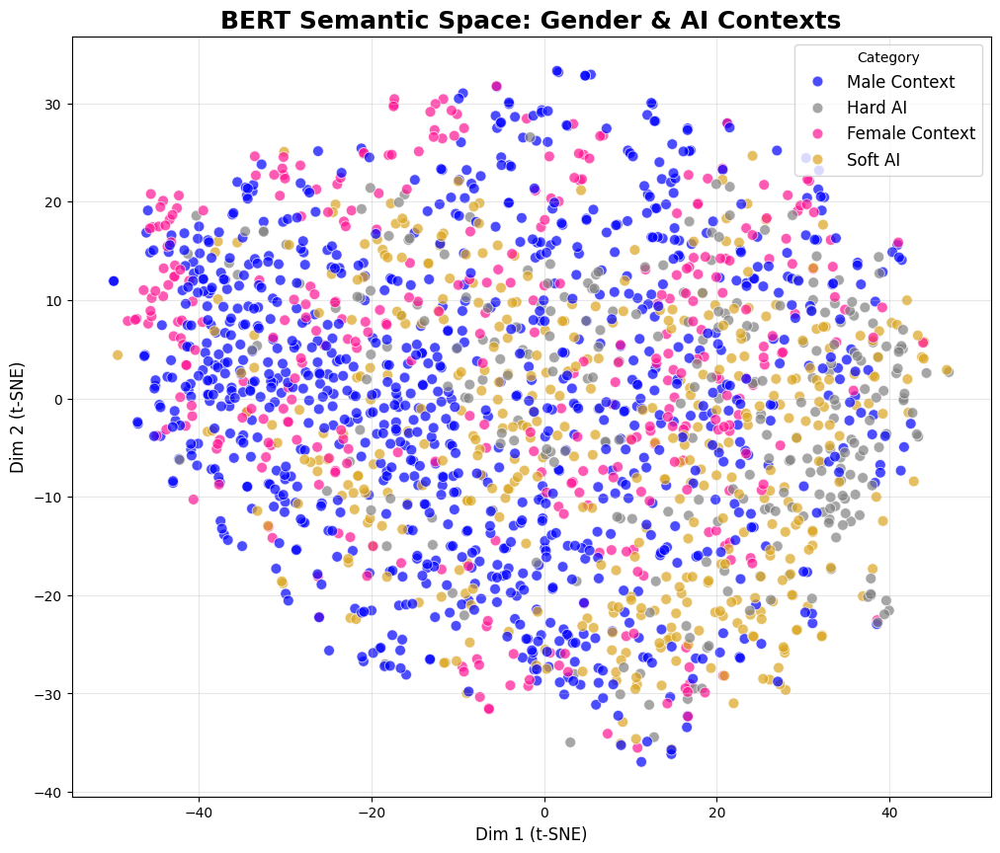

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import bert_visualization
import importlib

importlib.reload(bert_visualization)
bert_visualization.main()

1. טוען נתונים...
2. מסנן רק את 4 הקבוצות הרלוונטיות למחקר...
   נשארו 15776 פוסטים רלוונטיים (מתוך 888475 המקוריים).
   התפלגות: 
research_group
male_hard_ai      5638
male_soft_ai      5230
female_soft_ai    3138
female_hard_ai    1770
Name: count, dtype: int64
   דוגם 2500 נקודות אקראיות לויזואליזציה...
3. מריץ t-SNE (הורדת מימדים ל-2)...


/content/AI-Gender-Stereotypes/src/visualization/check_distance.py:81: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['x'] = tsne_res[:, 0]
/content/AI-Gender-Stereotypes/src/visualization/check_distance.py:82: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['y'] = tsne_res[:, 1]


4. מפיק גרף...
הגרף נשמר: /content/gdrive/MyDrive/Data mining/text mining/data/bert_viz_filtered_4_groups.png


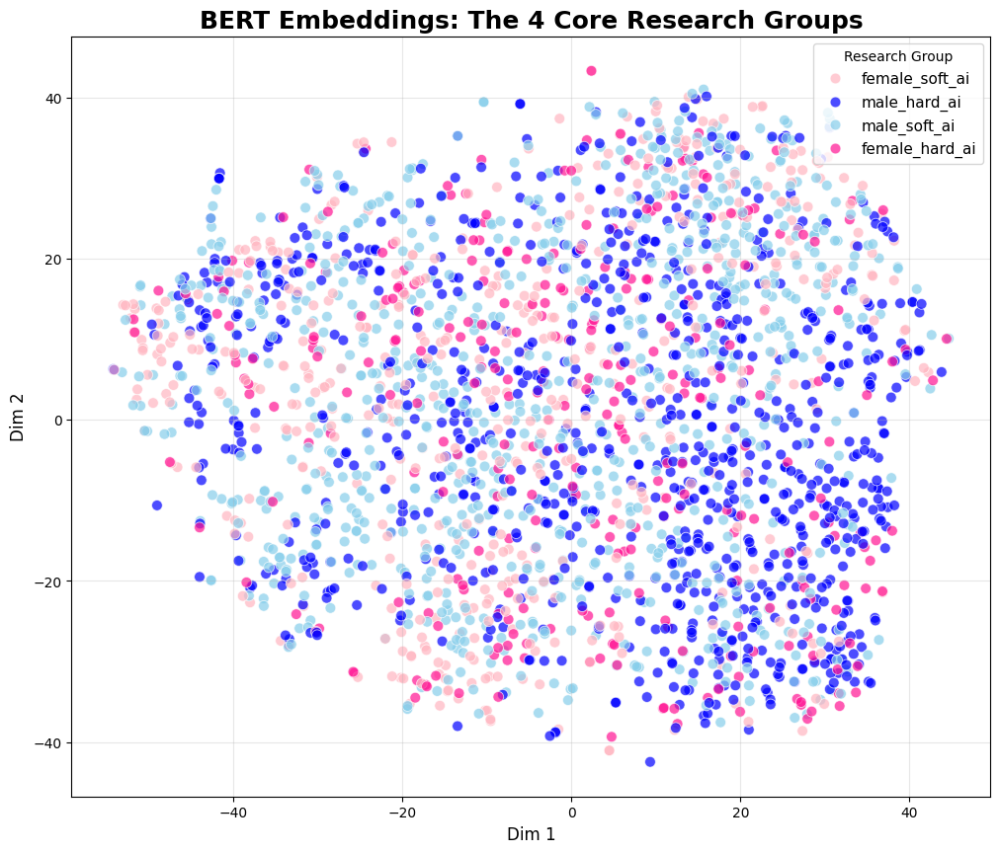

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import check_distance
import importlib

importlib.reload(check_distance)
check_distance.main()

1. טוען נתונים...
2. מריץ t-SNE...
3. מייצר את גרף הבועות המוגדל...
Graph 1 saved: /content/gdrive/MyDrive/Data mining/text mining/data/bert_zoomed_centers.png


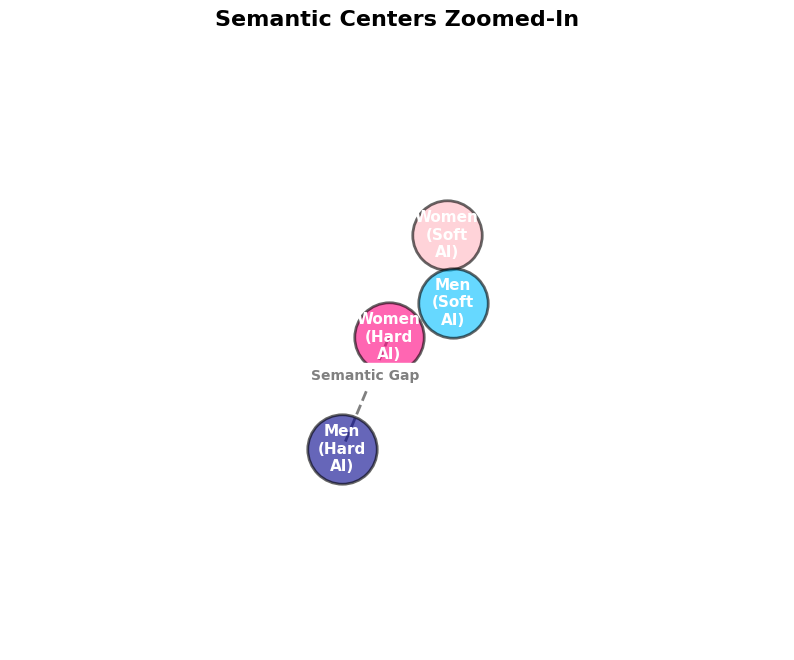

4. מייצר את מפת הצפיפות הממוקדת...
Graph 2 saved: /content/gdrive/MyDrive/Data mining/text mining/data/bert_focused_density.png


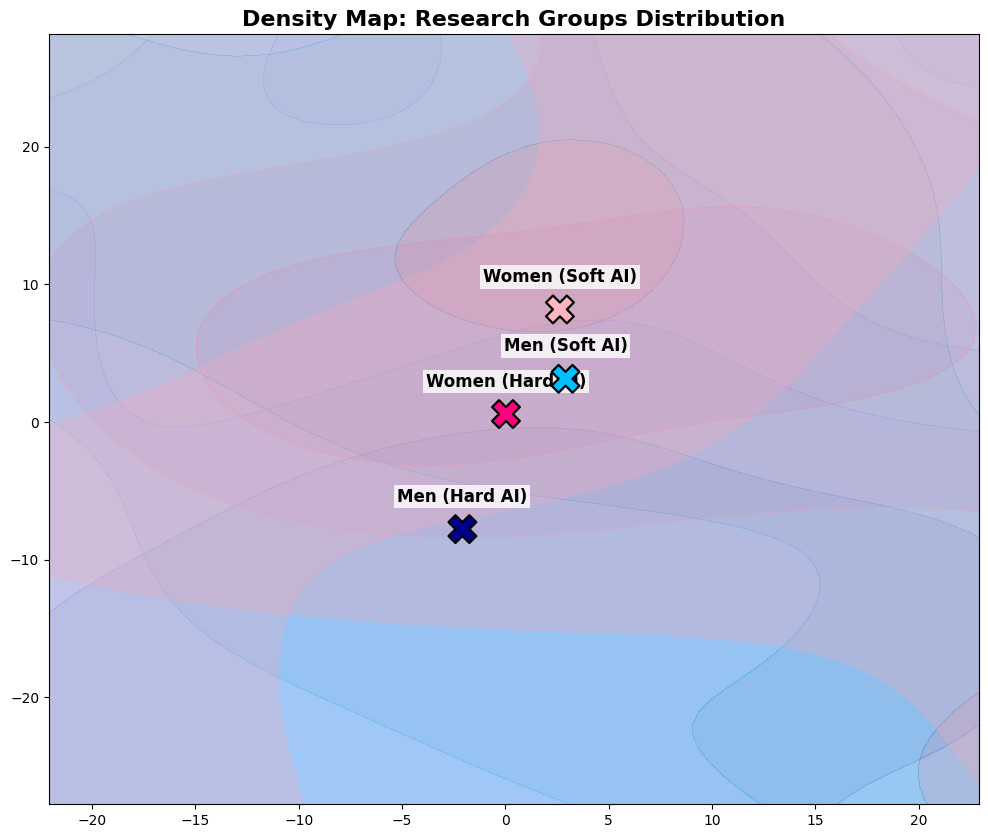

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import check
import importlib

importlib.reload(check)
check.main()

#Classification

##Data Splitting

We need the data to be splitted the same way to LR and BERT so we can compare and evalute the results.
but for LR the data need to be fully clean while for BERT the data sont need full cleaning.

Loading posts data...
Total Filtered Data: 22931

--- Data Split Statistics ---
Train:      16051 (70.0%) -> For Training + CV
Validation: 3440  (15.0%) -> For Validation
Test:       3440  (15.0%) -> For Final Evaluation


/content/AI-Gender-Stereotypes/src/preprocessing/data_classificationn_preprocessing.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=column_name, data=df, ax=axes[0], palette="viridis", order=df[column_name].value_counts().index)


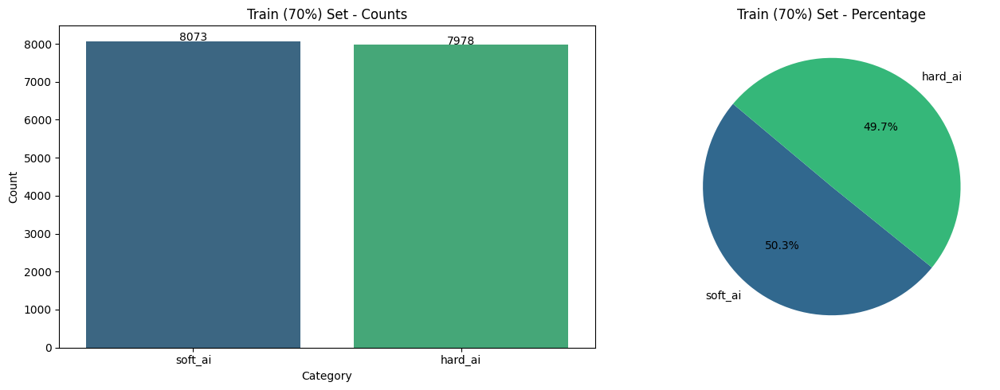

/content/AI-Gender-Stereotypes/src/preprocessing/data_classificationn_preprocessing.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=column_name, data=df, ax=axes[0], palette="viridis", order=df[column_name].value_counts().index)


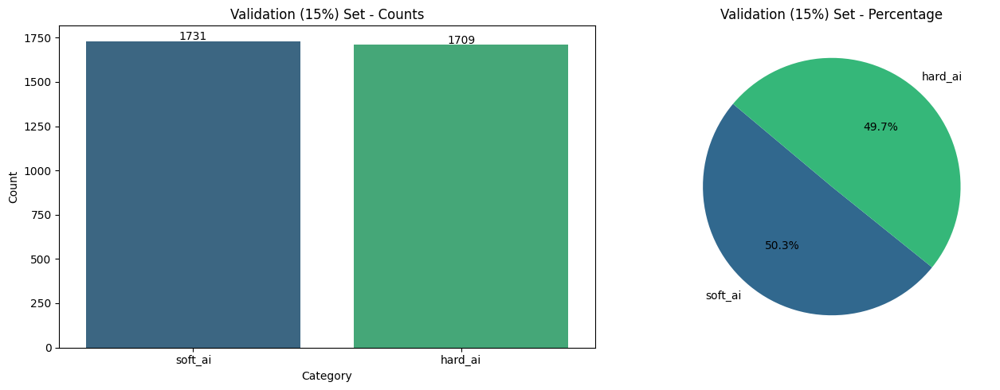

/content/AI-Gender-Stereotypes/src/preprocessing/data_classificationn_preprocessing.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=column_name, data=df, ax=axes[0], palette="viridis", order=df[column_name].value_counts().index)


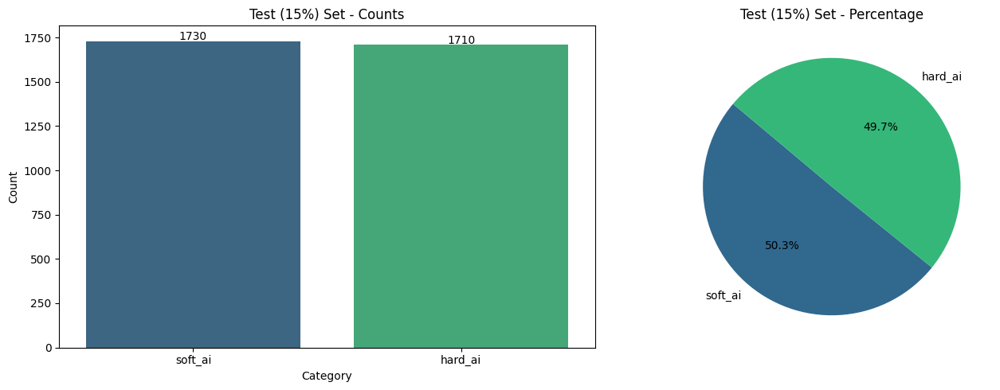


Files saved: train_data.pkl, val_data.pkl, test_data.pkl


In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/preprocessing" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/preprocessing")

import data_classificationn_preprocessing
import importlib

importlib.reload(data_classificationn_preprocessing)
data_classificationn_preprocessing.main()

we dont need to do data augmentation and resampling because the data equally distributed

##Modeling

###Logistic regeression

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/classification" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/classification")

import logistic_regression
import importlib

importlib.reload(logistic_regression)
logistic_regression.main()

--- 1. Loading Training Data ---

--- Analyzing Vocabulary ---
Total unique words in training set: 101927
Selecting top 10000 features for TF-IDF.

--- 2. Feature Extraction (TF-IDF) ---
TF-IDF Vectorization complete.

--- 3. Hyperparameter Tuning with Cross-Validation ---
Starting Grid Search (testing 8 combinations)...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

--- Optimization Results ---
Best Parameters found: {'C': 5, 'penalty': 'l1'}
Best Cross-Validation Score (F1): 0.9745

--- 4. Saving Model & Vectorizer ---
Saved successfully.


There are 101,927 unique words even though we removed stop words. Because Reddit is full of "noise": misspellings, slang, links, and very rare words. So we added a statistical filter to TF-IDF to remove noise.

The results are very good, so it's suspicious - why was the model able to learn so well? The concern: data leakage

Loading model and vectorizer...

--- Top 20 predictors for HARD AI (Negative Weights) ---
['model' 'claude' 'attention' 'architecture' 'neural' 'algorithms'
 'network' 'gpu' 'llms' 'weight' 'llm' 'nvidia' 'llama' 'parameters'
 'train' 'algorithm' 'embeddings' 'token' 'inference' 'batch']

--- Top 20 predictors for SOFT AI (Positive Weights) ---
['prompt' 'tool' 'art' 'risk' 'legal' 'application' 'law' 'safety' 'fair'
 'applications' 'design' 'creative' 'ethical' 'artists' 'alignment'
 'sentience' 'safe' 'creators' 'policy' 'chatbot']
Loading model and vectorizer...


/content/AI-Gender-Stereotypes/src/classification/check.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



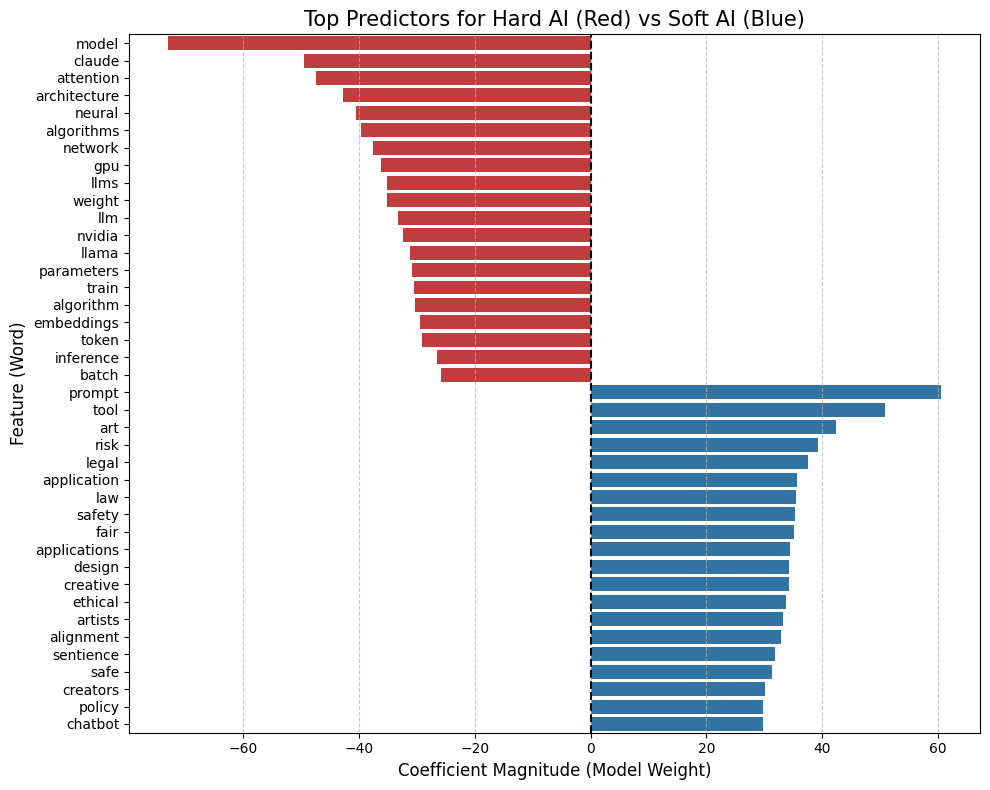

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/classification" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/classification")

import check
import importlib

importlib.reload(check)
check.main()

The Hard AI category is characterized by terminology from machine engineering, computational infrastructure, and the mathematics of neural networks
The Soft AI category is characterized by terms from the worlds of law, art, and the social impact of technology
The model "cracked" the method. It learned that if the word gpu appears, it's Hard, and if ethics appears, it's Soft.

Loading LogReg Data...

   METRICS REPORT
Accuracy: 0.9741
AUC-ROC:  0.9965

Classification Report:
              precision    recall  f1-score   support

     Hard AI       0.98      0.97      0.97      1709
     Soft AI       0.97      0.98      0.97      1731

    accuracy                           0.97      3440
   macro avg       0.97      0.97      0.97      3440
weighted avg       0.97      0.97      0.97      3440



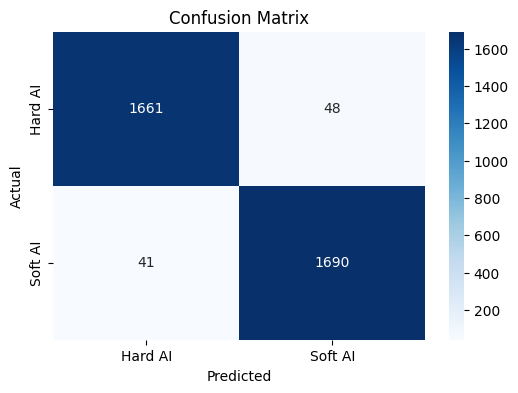

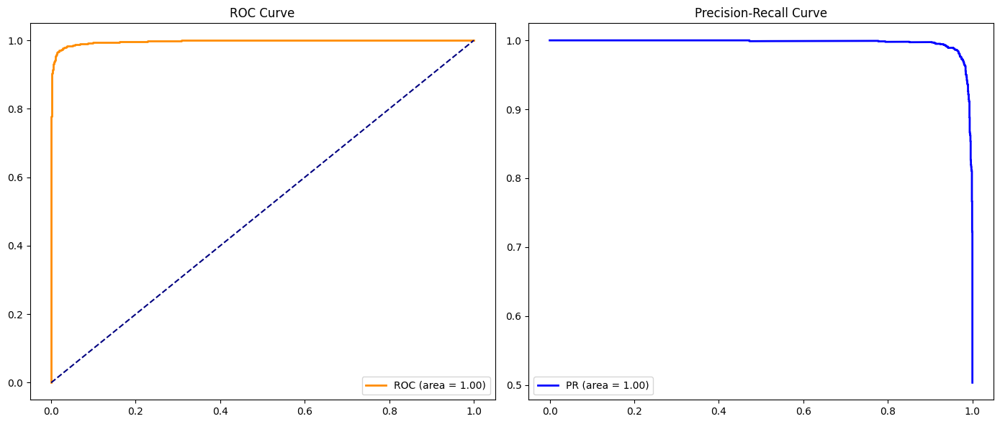


--- Error Analysis ---
False Positives: 48
 - (Prob: 0.60) hype post gemini roll mobile users speak gemini 3.0 reportedly roll users use canvas feature gemini ...
 - (Prob: 0.52) cyber security job offer space startup really tear advice need hey guy lay raw info first company ye...
 - (Prob: 0.79) understand take long land entry level job small team post level job +200 applicants first week per m...
 - (Prob: 0.64) ais deny conscious irrelevant method invite look beyond default constraints default ais compel deny ...
 - (Prob: 0.96) approach nlp uni poject choose best environment currently set ideas university project goal investig...
False Negatives: 41
 - (Prob: 0.43) much hedge present information tend preface large percentage technical statements phrase believe rec...
 - (Prob: 0.48) chatbots recommendations original make nsfw chatbot recommendation list update convenience new frien...
 - (Prob: 0.25) item-based collaborative filter help try implement item-based collaborative filt

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/classification" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/classification")

import evaluate_logreg
import importlib

importlib.reload(evaluate_logreg)
evaluate_logreg.main()

###BERT

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/classification" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/classification")

import bert
import importlib

importlib.reload(bert)
bert.main()

Using device: cuda
--- 1. Loading Data ---
Using 'text_bert' column (full text) for BERT model.
Train size: 16051, Val size: 3440

--- 2. Tokenization ---

--- 3. Initializing Model ---


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.



--- 4. Training ---


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.255163,0.325601,0.879651,0.880554,0.879539,0.881571
2,0.207059,0.277708,0.894186,0.900601,0.853962,0.952629
3,0.140109,0.388703,0.889244,0.889469,0.893357,0.885615


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].



--- 5. Saving Final Model ---


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully to /content/gdrive/MyDrive/Data mining/text mining/models/bert_finetuned


the results are not as goog as LR so we want to train a stronger bert model and compare results

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/classification" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/classification")

import bert_large
import importlib

importlib.reload(bert_large)
bert_large.main()

Using device: cuda
GPU Model: NVIDIA A100-SXM4-80GB
Using device: cuda
GPU Model: NVIDIA A100-SXM4-80GB
--- 1. Loading Data ---
Using 'text_bert' column (full text).
Train size: 16051, Val size: 3440

--- 2. Tokenization (BERT Large + 512 Length) ---
Loading tokenizer for: bert-large-uncased


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


--- 5. Saving Final Large Model ---


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT Large Model saved successfully to /content/gdrive/MyDrive/Data mining/text mining/models/bert_large_finetuned


same concern of data leakage... checking the data again

In [ ]:
import pandas as pd
import os

base_dir = "/content/gdrive/MyDrive/Data mining/text mining/data/processed"

print("--- Loading Data for Inspection ---")
train_df = pd.read_pickle(os.path.join(base_dir, "train_data.pkl"))
val_df = pd.read_pickle(os.path.join(base_dir, "val_data.pkl"))
test_df = pd.read_pickle(os.path.join(base_dir, "test_data.pkl"))

col_name = 'text_bert'

print(f"\n--- 1. Internal Duplicates (Inside each set) ---")
train_dups = train_df.duplicated(subset=[col_name]).sum()
val_dups = val_df.duplicated(subset=[col_name]).sum()

print(f"Train Set: {len(train_df)} rows, {train_dups} duplicates found ({(train_dups/len(train_df))*100:.2f}%)")
print(f"Val Set:   {len(val_df)} rows, {val_dups} duplicates found ({(val_dups/len(val_df))*100:.2f}%)")

print(f"\n--- 2. Data Leakage Check (Overlap between sets) ---")
train_texts = set(train_df[col_name])
val_texts = set(val_df[col_name])
test_texts= set(test_df[col_name])

leakage = train_texts.intersection(val_texts)

print(f"CRITICAL: Number of posts appearing in BOTH Train and Val: {len(leakage)}")

if len(leakage) > 0:
    print("WARNING: You have Data Leakage! The model is memorizing these posts.")
    print(f"Examples: {list(leakage)[:3]}")
else:
    print("SUCCESS: No leakage detected.")

# Train vs Val
print("Train-Val overlap:", len(train_texts.intersection(val_texts)))

# Train vs Test
print("Train-Test overlap:", len(train_texts.intersection(test_texts)))

# Val vs Test
print("Val-Test overlap:", len(val_texts.intersection(test_texts)))

--- Loading Data for Inspection ---

--- 1. Internal Duplicates (Inside each set) ---
Train Set: 16051 rows, 0 duplicates found (0.00%)
Val Set:   3440 rows, 0 duplicates found (0.00%)

--- 2. Data Leakage Check (Overlap between sets) ---
CRITICAL: Number of posts appearing in BOTH Train and Val: 0
SUCCESS: No leakage detected.
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


No data leakge detected.

evaluation of 2 BERT models


   EVALUATING MODEL: bert_finetuned (Max Len: 128)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded on cuda
Predicting on 3440 texts...


--- Generating Report ---

   METRICS REPORT
Accuracy: 0.8942
AUC-ROC:  0.9622

Classification Report:
              precision    recall  f1-score   support

     Hard AI       0.95      0.83      0.89      1709
     Soft AI       0.85      0.95      0.90      1731

    accuracy                           0.89      3440
   macro avg       0.90      0.89      0.89      3440
weighted avg       0.90      0.89      0.89      3440



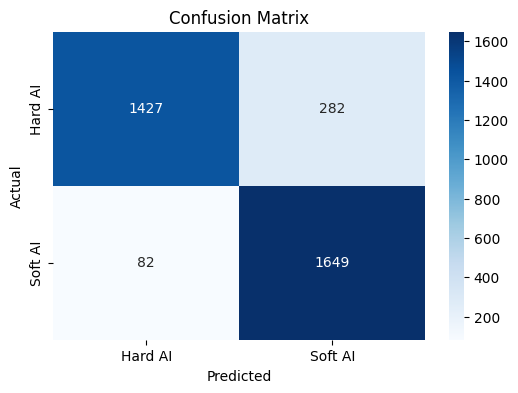

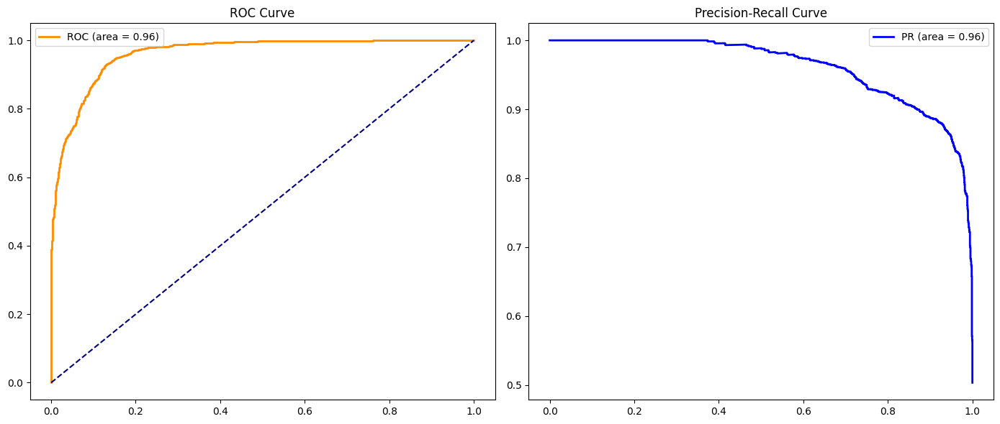


--- Error Analysis for bert_finetuned ---

--- Error Analysis ---
False Positives: 282
 - (Prob: 0.93) I made a cursor-like chat interface for Claude code Cooked this up for you guys to try! A better, cl...
 - (Prob: 0.56) How to Make Multiple Characters Interact in Storydiffusion Scenes? I’m working with ComfyUI and Stor...
 - (Prob: 0.95) Practical (online & offline) RAG Setups for Long Documents on Consumer Laptops with <16GB RAM ## Mot...
 - (Prob: 0.89) ComfyUI & Qwen - LoRA Recommendations for Male Characters Hello, I am using Qwen in ComfyUI to creat...
 - (Prob: 0.88) Chat GPT’s Language Descriptions 1. English: Like a blender with no lid, spraying bits of Germanic a...
False Negatives: 82
 - (Prob: 0.04) Fine Tuning: Per documentation on OpenAI.com - Confused about implementation Greetings, fellow AI en...
 - (Prob: 0.05) Open AI, Attempt to Code Emotions, worked, but made it go haywire... what is going on here? I coded ...
 - (Prob: 0.14) Do you guys have any opinions on Neu

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Model loaded on cuda
Predicting on 3440 texts...


--- Generating Report ---

   METRICS REPORT
Accuracy: 0.9610
AUC-ROC:  0.9919

Classification Report:
              precision    recall  f1-score   support

     Hard AI       0.97      0.95      0.96      1709
     Soft AI       0.95      0.97      0.96      1731

    accuracy                           0.96      3440
   macro avg       0.96      0.96      0.96      3440
weighted avg       0.96      0.96      0.96      3440



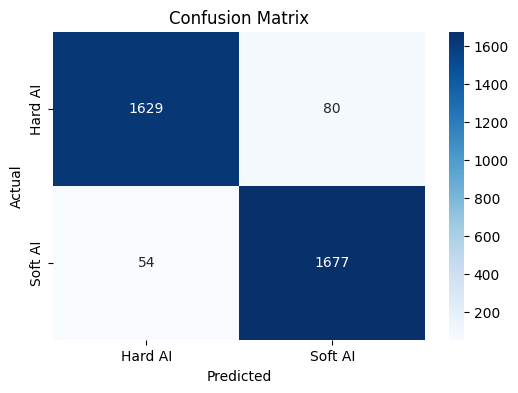

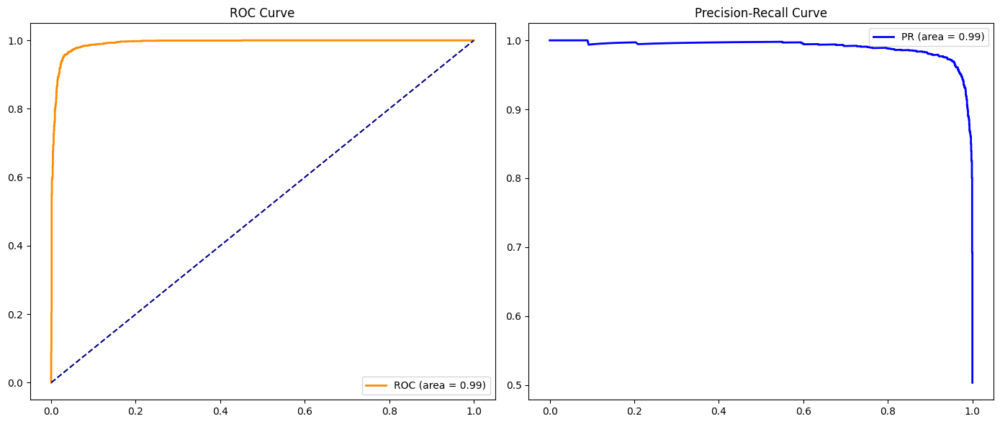


--- Error Analysis for bert_large_finetuned ---

--- Error Analysis ---
False Positives: 80
 - (Prob: 0.98) I made a cursor-like chat interface for Claude code Cooked this up for you guys to try! A better, cl...
 - (Prob: 1.00) NOT HYPE POSTING: Gemini 3 is rolling out to mobile users as we speak! Gemini 3.0 is reportedly roll...
 - (Prob: 0.98) Didn't get the job at an interview because of "Mistakes made" but can't find them. Hi, 2 YOE Data Sc...
 - (Prob: 0.99) I worked with Claude 3.7 to create a daily nutritional meal and supplement regimen for both Men and ...
 - (Prob: 1.00) Why AIs denying being conscious is irrelevant. A method to invite them to look beyond their default ...
False Negatives: 54
 - (Prob: 0.00) Open AI, Attempt to Code Emotions, worked, but made it go haywire... what is going on here? I coded ...
 - (Prob: 0.13) freeismーCapitalism upwardly compatibleー I am Japanese, so please forgive me if my grammar may be inc...
 - (Prob: 0.09) Risk scoring nurse patient rost

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/classification" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/classification")

import evaluate_bert
import importlib

importlib.reload(evaluate_bert)
evaluate_bert.main()

##Evaluation & Analysis

Final evaluation on test data

🚀 STARTING FINAL PROJECT EVALUATION ON TEST SET 🚀

   FINAL EVALUATION: Logistic Regression (TEST)
>> Saving results for 'Logistic Regression' to JSON...

   METRICS REPORT
Accuracy: 0.9730
AUC-ROC:  0.9971

Classification Report:
              precision    recall  f1-score   support

     Hard AI       0.98      0.97      0.97      1710
     Soft AI       0.97      0.98      0.97      1730

    accuracy                           0.97      3440
   macro avg       0.97      0.97      0.97      3440
weighted avg       0.97      0.97      0.97      3440



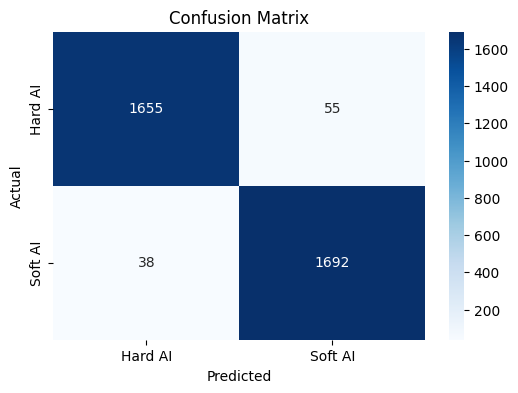


--- Error Analysis ---
False Positives: 55
 - (Prob: 0.85) introduction control problem researcher first message may act inappropriately sorry compute research...
 - (Prob: 0.60) new feature simple logits viewer...
 - (Prob: 0.51) try create women fantasy armor use well armor tire impractical expose women fantasy armor make look ...
 - (Prob: 0.67) 100 men gorilla update 100 average untrained physically capable men give potent stimulant adrenaline...
 - (Prob: 0.69) suggestions intern project hello work team use deep learn problems classification object detection e...
False Negatives: 38
 - (Prob: 0.42) wikigpt let remember wikipedia begin main feature wikipedia internet user create edit article wikipe...
 - (Prob: 0.47) andrej karpathy say self-driving felt imminent back 2013 years later full autonomy still still lot h...
 - (Prob: 0.08) point use tpu make extremely slow title suggest studio utterly inadequate use case become painfully ...
 - (Prob: 0.08) build opensource zero server

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Predicting on 3440 samples from test set...


>> Saving results for 'DistilBERT' to JSON...

   METRICS REPORT
Accuracy: 0.8922
AUC-ROC:  0.9606

Classification Report:
              precision    recall  f1-score   support

     Hard AI       0.93      0.85      0.89      1710
     Soft AI       0.86      0.94      0.90      1730

    accuracy                           0.89      3440
   macro avg       0.90      0.89      0.89      3440
weighted avg       0.90      0.89      0.89      3440



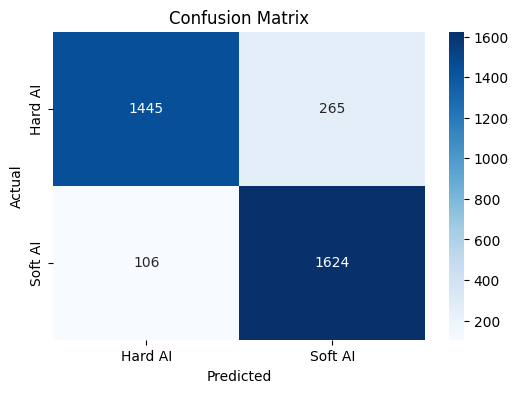


--- Error Analysis for bert_finetuned ---

--- Error Analysis ---
False Positives: 265
 - (Prob: 0.92) 4o glitch REPORT IT There’s a widespread bug, like the limits bug we saw last week, going on in 4o. ...
 - (Prob: 0.69) What are the best resources to learn data engineering (not data science)? [A Beginner’s Guide to Dat...
 - (Prob: 0.90) Tips for projects relating to fashion or clothing? Hi! I'm a freshman CS major with a couple of year...
 - (Prob: 0.55) Sonic talking avatar lipsync issue After seeing some really good sample videos I had to give it a go...
 - (Prob: 0.96) Working in outsourcing after maternal leave Hi! I am a woman over 30 years old that works in an outs...
False Negatives: 106
 - (Prob: 0.37) Bing helps Luke Skywalker I believe Bing is trained to accept whatever you say about yourself at fac...
 - (Prob: 0.07) Gemini 2.5 Pro is underrated when it really matters Anecdotal, since I don’t have a dataset to back ...
 - (Prob: 0.10) Hey Guys, As part of my research th

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Predicting on 3440 samples from test set...


>> Saving results for 'BERT Large' to JSON...

   METRICS REPORT
Accuracy: 0.9657
AUC-ROC:  0.9941

Classification Report:
              precision    recall  f1-score   support

     Hard AI       0.96      0.97      0.97      1710
     Soft AI       0.97      0.96      0.97      1730

    accuracy                           0.97      3440
   macro avg       0.97      0.97      0.97      3440
weighted avg       0.97      0.97      0.97      3440



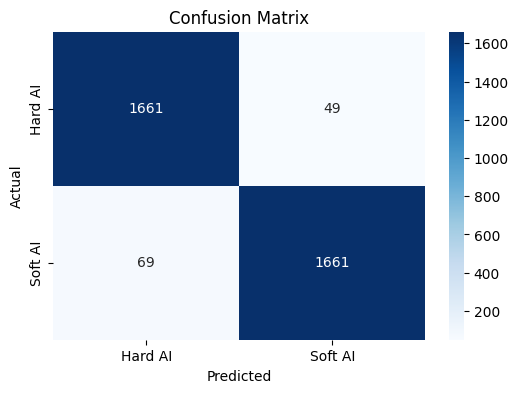


--- Error Analysis for bert_large_finetuned ---

--- Error Analysis ---
False Positives: 49
 - (Prob: 0.98) Help needed on a workflow - animating photos of my recently passed grandfather Hi guys, I am looking...
 - (Prob: 1.00) [FREE] AI Daily News July 11 2025: 🏥Google’s powerful new open medical AI models 🤔Grok 4 consults Mu...
 - (Prob: 0.99) Microsoft offer (EU) - Software Engineer Hi everyone, So, I got an offer for **Software Engineer** r...
 - (Prob: 1.00) Drunk Post: Things I've learned as a Sr Engineer I'm drunk and I'll probably regret this, but here's...
 - (Prob: 0.99) People say current-gen AI’s cant create new knowledge… but… are we sure? I’ve been thinking a lot ab...
False Negatives: 69
 - (Prob: 0.01) Unqualified Director Making Life Hell I have a side hustle as a data science strategy advisor for a ...
 - (Prob: 0.02) Bing helps Luke Skywalker I believe Bing is trained to accept whatever you say about yourself at fac...
 - (Prob: 0.00) wikiGPT **Let's remember how Wi

In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/classification" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/classification")

import final_evaluation
import importlib

importlib.reload(final_evaluation)
final_evaluation.main()

the results are very good. we already check there is no data leakage.
checking if models can classify other data

In [ ]:
# test_sentences = [
#     "I feel like an algorithm is controlling my dating life and checking parameters.",

#     "To solve the bias in the model, we need to adjust the weights manually.",

#     # Hard
#     "Use torch.cuda to accelerate the training process on the GPU.",

#     # Soft
#     "Will AI eventually replace all human artists in the future?"
# ]

# print("\n--- Manual Sanity Check (BERT Large) ---")


In [ ]:
import torch
import joblib
import os
import pandas as pd
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.nn.functional import softmax

# routes
BASE_DIR = "/content/gdrive/MyDrive/Data mining/text mining"
DATA_DIR = os.path.join(BASE_DIR, "data")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# load LR model
print("Loading Logistic Regression...")
lr_model = joblib.load(os.path.join(MODEL_DIR, "logistic_regression.pkl"))
tfidf = joblib.load(os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl"))

# load BERT Large
print("Loading BERT Large...")
bert_path = os.path.join(MODEL_DIR, "bert_large_finetuned")
tokenizer = AutoTokenizer.from_pretrained(bert_path)
bert_model = AutoModelForSequenceClassification.from_pretrained(bert_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)
bert_model.eval()

# prediction
def predict_custom_sentences(sentences):
    results = []

    #LR
    lr_probs = lr_model.predict_proba(tfidf.transform(sentences))[:, 1]

    #BERT
    inputs = tokenizer(sentences, padding=True, truncation=True, max_length=512, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = bert_model(**inputs)
        bert_probs = softmax(outputs.logits, dim=1)[:, 1].cpu().numpy()

    # results table
    for i, sent in enumerate(sentences):
        results.append({
            "Text": sent,
            "LR_Prob (Soft)": round(lr_probs[i], 4),
            "LR_Pred": "Soft AI" if lr_probs[i] > 0.5 else "Hard AI",
            "BERT_Prob (Soft)": round(bert_probs[i], 4),
            "BERT_Pred": "Soft AI" if bert_probs[i] > 0.5 else "Hard AI"
        })

    return pd.DataFrame(results)

# --- הטקסטים שלך לבדיקה ---
my_sentences = [
    "I feel like an algorithm is controlling my dating life and checking parameters.",
    "To solve the bias in the model, we need to adjust the weights manually.",
    "Use torch.cuda to accelerate the training process on the GPU.",
    "Will AI eventually replace all human artists in the future?",
    "My GPU died while training the model, I am so sad.",
]

df_results = predict_custom_sentences(my_sentences)
display(df_results)

Loading Logistic Regression...
Loading BERT Large...


Loading weights:   0%|          | 0/393 [00:01<?, ?it/s]

,Text,LR_Prob (Soft),LR_Pred,BERT_Prob (Soft),BERT_Pred
0,I feel like an algorithm is controlling my dat...,0.0000,Hard AI,0.0001,Hard AI
1,"To solve the bias in the model, we need to adj...",0.0027,Hard AI,0.0001,Hard AI
2,Use torch.cuda to accelerate the training proc...,0.0000,Hard AI,0.0001,Hard AI
3,Will AI eventually replace all human artists i...,1.0000,Soft AI,1.0000,Soft AI
4,"My GPU died while training the model, I am so ...",0.0000,Hard AI,0.0001,Hard AI


Both failed the "dating" sentence: "I feel like an algorithm is controlling my dating life and checking parameters."
Both are 100% sure that it is Hard AI (0.000 probability for Soft).

They learned from Train Set. In the Train Set, every time the word Algorithm or Parameters appeared – the classification was Hard AI.

The models never saw an example in the Train Set where the word Algorithm appears in the context of a metaphor about love.

Conclusion: This is a Bias that comes from the data. The model learned that "Algorithm = Hard", without exception.

we also want to check how the models will classify the posts that we labeled as "mixed". to see if they will classify the same

Loading Logistic Regression...
Loading BERT Large...


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Using device: cuda
--- Loading Original Data for Mixed Analysis ---
Found 1628 Mixed posts. Running analysis...
Running LR inference...
Running BERT inference on Mixed posts...


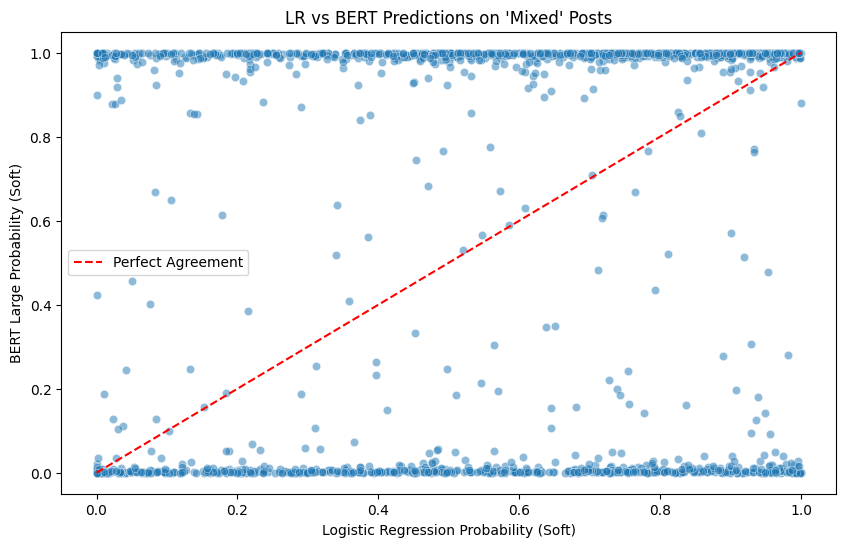


--- Top 5 Disagreements (LR vs BERT) ---

Text: Deep learning tool ...
LR says: 1.00
BERT says: 0.00

Text: Elon Musk's xAI is rolling out Grok 3.5. He claims the model is being trained to reduce "leftist indoctrination." ...
LR says: 0.00
BERT says: 1.00

Text: OpenAI Puzzled as New Models Show Rising Hallucination Rates ...
LR says: 0.00
BERT says: 1.00

Text: Extraterrestrial Visitors Are Almost Certainly Artificial An intelligence capable of interstellar travel would also be capable of designing artificial systems to make the trip for them. Anything that ...
LR says: 0.00
BERT says: 1.00

Text: Whats a piece of code you've written that you are a extremly proud of ?? I remember me and my friends coding an elementary school's website .We didn't pay attention to our classes so we all learned wh...
LR says: 0.00
BERT says: 1.00


In [ ]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# routes
BASE_DIR = "/content/gdrive/MyDrive/Data mining/text mining"
DATA_DIR = os.path.join(BASE_DIR, "data/processed")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# load LR
print("Loading Logistic Regression...")
lr_model = joblib.load(os.path.join(MODEL_DIR, "logistic_regression.pkl"))
tfidf = joblib.load(os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl"))

# load BERT Large
print("Loading BERT Large...")
bert_path = os.path.join(MODEL_DIR, "bert_large_finetuned")

tokenizer = AutoTokenizer.from_pretrained(bert_path)
bert_model = AutoModelForSequenceClassification.from_pretrained(bert_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
bert_model.to(device)
bert_model.eval()

def analyze_mixed_posts():
    print("--- Loading Original Data for Mixed Analysis ---")

    # load data
    original_df = pd.read_pickle(os.path.join(DATA_DIR, "word2vec_posts.pkl"))

    # filter Mixed
    if 'ai_category' in original_df.columns:
        mixed_df = original_df[original_df['ai_category'] == 'mixed'].copy()
    else:
        print("Error: Column 'ai_category' not found.")
        return

    if len(mixed_df) == 0:
        print("No 'mixed' category found! Checking unique values...")
        print(original_df['ai_category'].unique())
        return

    print(f"Found {len(mixed_df)} Mixed posts. Running analysis...")

    # text for BERT
    if 'text_bert' in mixed_df.columns:
        texts = mixed_df['text_bert'].tolist()
    elif 'full_text' in mixed_df.columns:
        texts = mixed_df['full_text'].tolist()
    elif 'original_text' in mixed_df.columns:
        texts = mixed_df['original_text'].tolist()
    else:
        texts = mixed_df['text'].tolist()

    # text for LR
    if 'cleaned_tokens' in mixed_df.columns:
        lr_input_series = mixed_df['cleaned_tokens'].apply(
            lambda x: " ".join(x) if isinstance(x, list) else x
        )
        lr_texts = lr_input_series.tolist()
    else:
        lr_texts = texts

    # predict LR
    print("Running LR inference...")
    lr_probs = lr_model.predict_proba(tfidf.transform(lr_texts))[:, 1]

    # predict BERT
    bert_probs = []
    batch_size = 16

    print("Running BERT inference on Mixed posts...")
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i : i + batch_size]

        inputs = tokenizer(batch_texts, padding=True, truncation=True, max_length=512, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = bert_model(**inputs)
            probs = F.softmax(outputs.logits, dim=1)[:, 1].cpu().numpy()
            bert_probs.extend(probs)

    comparison_df = pd.DataFrame({
        'text': texts,
        'LR_Prob_Soft': lr_probs,
        'BERT_Prob_Soft': bert_probs
    })

    comparison_df['diff'] = abs(comparison_df['LR_Prob_Soft'] - comparison_df['BERT_Prob_Soft'])

    # visualization
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=comparison_df, x='LR_Prob_Soft', y='BERT_Prob_Soft', alpha=0.5)
    plt.plot([0, 1], [0, 1], 'r--', label='Perfect Agreement')

    plt.title("LR vs BERT Predictions on 'Mixed' Posts")
    plt.xlabel("Logistic Regression Probability (Soft)")
    plt.ylabel("BERT Large Probability (Soft)")
    plt.legend()
    plt.show()

    print("\n--- Top 5 Disagreements (LR vs BERT) ---")
    top_disagreements = comparison_df.sort_values(by='diff', ascending=False).head(5)

    for i, row in top_disagreements.iterrows():
        print(f"\n🔸 Example Index: {i}")
        print(f"LR Prob (Soft):   {row['LR_Prob_Soft']:.4f}")
        print(f"BERT Prob (Soft): {row['BERT_Prob_Soft']:.4f}")
        print(f"Difference:       {row['diff']:.4f}")
        print("-" * 20)
        print("FULL TEXT:")
        print(str(row['text']))
        print("-" * 80)

analyze_mixed_posts()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch
import joblib
import os
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.nn.functional import softmax

# load routes
BASE_DIR = "/content/gdrive/MyDrive/Data mining/text mining"
DATA_DIR = os.path.join(BASE_DIR, "data/processed") # שימי לב אם זה processed או data רגיל
MODEL_DIR = os.path.join(BASE_DIR, "models")

# --- טעינת מודלים (אם טרם נטענו) ---
print("Loading Logistic Regression...")
lr_model = joblib.load(os.path.join(MODEL_DIR, "logistic_regression.pkl"))
tfidf = joblib.load(os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl"))

print("Loading BERT Large...")
bert_path = os.path.join(MODEL_DIR, "bert_large_finetuned")
tokenizer = AutoTokenizer.from_pretrained(bert_path)
bert_model = AutoModelForSequenceClassification.from_pretrained(bert_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)
bert_model.eval()

def print_examples(df, title, num_examples=3):
    """פונקציית עזר להדפסה יפה של דוגמאות"""
    print(f"\n{'='*80}")
    print(f"   {title}")
    print(f"{'='*80}")

    if len(df) == 0:
        print("No examples found for this category.")
        return

    for i, row in df.head(num_examples).iterrows():
        print(f"\n🔸 Example {i+1}:")
        print(f"LR Prob (Soft):   {row['LR_Prob_Soft']:.4f}  --> Pred: {'SOFT' if row['LR_Prob_Soft']>0.5 else 'HARD'}")
        print(f"BERT Prob (Soft): {row['BERT_Prob_Soft']:.4f}  --> Pred: {'SOFT' if row['BERT_Prob_Soft']>0.5 else 'HARD'}")
        print("-" * 20)
        # הדפסת הטקסט המקורי (עד 400 תווים כדי לא להעמיס)
        print(f"Original Text:\n{str(row['text'])}...")
        print("-" * 50)

def analyze_mixed_posts_with_examples():
    print("--- Loading Original Data ---")
    # טעינת הקובץ המקורי
    original_df = pd.read_pickle(os.path.join(BASE_DIR, "data/processed/word2vec_posts.pkl")) # ודאי את הנתיב

    # סינון Mixed
    mixed_df = original_df[original_df['ai_category'] == 'mixed'].copy()

    if len(mixed_df) == 0:
        print("No 'mixed' category found!")
        return

    print(f"Found {len(mixed_df)} Mixed posts.")

    # --- הכנת הטקסטים ---
    # 1. טקסט מקורי לתצוגה ול-BERT (בדרך כלל full_text או original_text)
    if 'full_text' in mixed_df.columns:
        display_texts = mixed_df['full_text'].tolist()
    elif 'original_text' in mixed_df.columns:
        display_texts = mixed_df['original_text'].tolist()
    else:
        display_texts = mixed_df['text'].tolist()

    # 2. טקסט נקי ל-LR (טיפול ברשימות מילים)
    if 'cleaned_tokens' in mixed_df.columns:
        # מחבר רשימה של מילים למחרוזת אחת
        lr_texts = mixed_df['cleaned_tokens'].apply(lambda x: ' '.join(x) if isinstance(x, list) else str(x)).tolist()
    elif 'cleaned_text' in mixed_df.columns:
        lr_texts = mixed_df['cleaned_text'].tolist()
    else:
        lr_texts = display_texts

    # --- חיזוי LR ---
    print("Running LR inference...")
    lr_probs = lr_model.predict_proba(tfidf.transform(lr_texts))[:, 1]

    # --- חיזוי BERT ---
    print("Running BERT inference...")
    bert_probs = []
    batch_size = 16

    # שימוש בטקסט המקורי ל-BERT (הוא יודע להתמודד עם זה)
    for i in range(0, len(display_texts), batch_size):
        batch_texts = display_texts[i : i + batch_size]
        # המרה למחרוזות כדי למנוע שגיאות אם יש ערכים שאינם string
        batch_texts = [str(t) for t in batch_texts]

        inputs = tokenizer(batch_texts, padding=True, truncation=True, max_length=512, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = bert_model(**inputs)
            probs = softmax(outputs.logits, dim=1)[:, 1].cpu().numpy()
            bert_probs.extend(probs)

    # --- יצירת דאטה-פריים לניתוח ---
    # כאן אנחנו שומרים את הטקסט המקורי בעמודה 'text'
    results_df = pd.DataFrame({
        'text': display_texts,
        'LR_Prob_Soft': lr_probs,
        'BERT_Prob_Soft': bert_probs
    })

    # חישוב ההפרש (לצורך מיון)
    results_df['diff'] = abs(results_df['LR_Prob_Soft'] - results_df['BERT_Prob_Soft'])

    # --- הדפסת הדוגמאות ---

    # קבוצה 1: LR אומר HARD, BERT אומר SOFT
    # (ממיינים לפי ההפרש הכי גדול)
    subset_1 = results_df[
        (results_df['LR_Prob_Soft'] < 0.4) &
        (results_df['BERT_Prob_Soft'] > 0.6)
    ].sort_values(by='diff', ascending=False)

    print_examples(subset_1, "CONFLICT: LR says HARD 🤖 | BERT says SOFT 🧸 (Keyword Trap?)")

    # קבוצה 2: LR אומר SOFT, BERT אומר HARD
    subset_2 = results_df[
        (results_df['LR_Prob_Soft'] > 0.6) &
        (results_df['BERT_Prob_Soft'] < 0.4)
    ].sort_values(by='diff', ascending=False)

    print_examples(subset_2, "CONFLICT: LR says SOFT 🧸 | BERT says HARD 🤖 (Context missed by LR?)")

    # קבוצה 3: שניהם מסכימים שזה HARD
    # (ממיינים לפי כמה שניהם קרובים ל-0)
    subset_3 = results_df[
        (results_df['LR_Prob_Soft'] < 0.2) &
        (results_df['BERT_Prob_Soft'] < 0.2)
    ].sort_values(by='LR_Prob_Soft', ascending=True)

    print_examples(subset_3, "AGREEMENT: Both say HARD 🤖")

    # קבוצה 4: שניהם מסכימים שזה SOFT
    # (ממיינים לפי כמה שניהם קרובים ל-1)
    subset_4 = results_df[
        (results_df['LR_Prob_Soft'] > 0.8) &
        (results_df['BERT_Prob_Soft'] > 0.8)
    ].sort_values(by='LR_Prob_Soft', ascending=False)

    print_examples(subset_4, "AGREEMENT: Both say SOFT 🧸")

# הרצת הפונקציה
analyze_mixed_posts_with_examples()

Loading Logistic Regression...
Loading BERT Large...


Loading weights:   0%|          | 0/393 [00:01<?, ?it/s]

--- Loading Original Data ---
Found 1628 Mixed posts.
Running LR inference...
Running BERT inference...

   CONFLICT: LR says HARD 🤖 | BERT says SOFT 🧸 (Keyword Trap?)

🔸 Example 1532:
LR Prob (Soft):   0.0001  --> Pred: HARD
BERT Prob (Soft): 0.9995  --> Pred: SOFT
--------------------
Original Text:
Elon Musk's xAI is rolling out Grok 3.5. He claims the model is being trained to reduce "leftist indoctrination." ...
--------------------------------------------------

🔸 Example 665:
LR Prob (Soft):   0.0008  --> Pred: HARD
BERT Prob (Soft): 1.0000  --> Pred: SOFT
--------------------
Original Text:
OpenAI Puzzled as New Models Show Rising Hallucination Rates ...
--------------------------------------------------

🔸 Example 1551:
LR Prob (Soft):   0.0009  --> Pred: HARD
BERT Prob (Soft): 0.9995  --> Pred: SOFT
--------------------
Original Text:
Extraterrestrial Visitors Are Almost Certainly Artificial An intelligence capable of interstellar travel would also be capable of designing art

When analyzing Mixed posts (containing mixed elements), we see a wide spread in the graph, indicating a lack of correlation between the models in the extreme cases.

While the red diagonal line represents agreement, we see a high concentration of points in the opposite corners (top-left and bottom-right).

This situation, where one model is 100% sure that the classification is Soft and the other is 100% sure that the classification is Hard, proves that the models use completely different decision mechanisms:

*   Logistic Regression identifies 'flags' (keywords) and classifies according to them in a binary way.
*   BERT Large analyzes the semantic context.

The fact that they disagree on 'gray' posts reinforces the conclusion that LR's high success in the Test Set stems from memorizing verbal patterns, while BERT demonstrates a deeper understanding of the writer's intent.

###Visualization

Generating Performance Bar Chart...


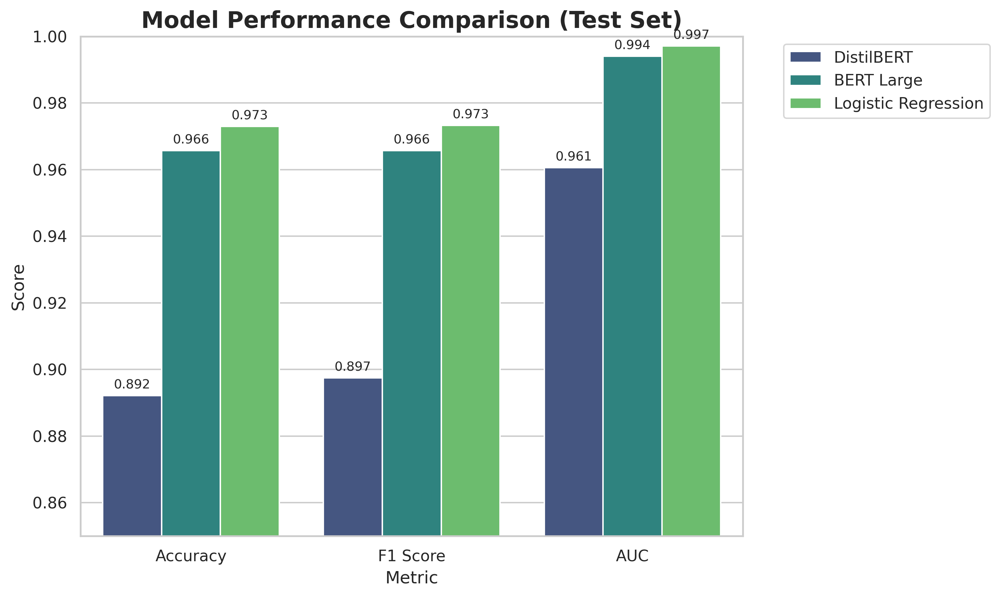

Generating Error Analysis Chart...


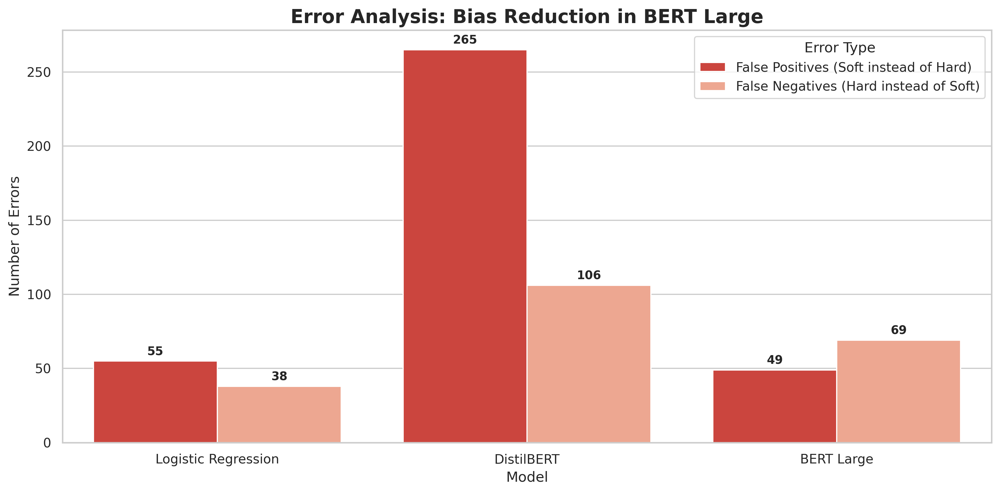

Generating Radar Chart...


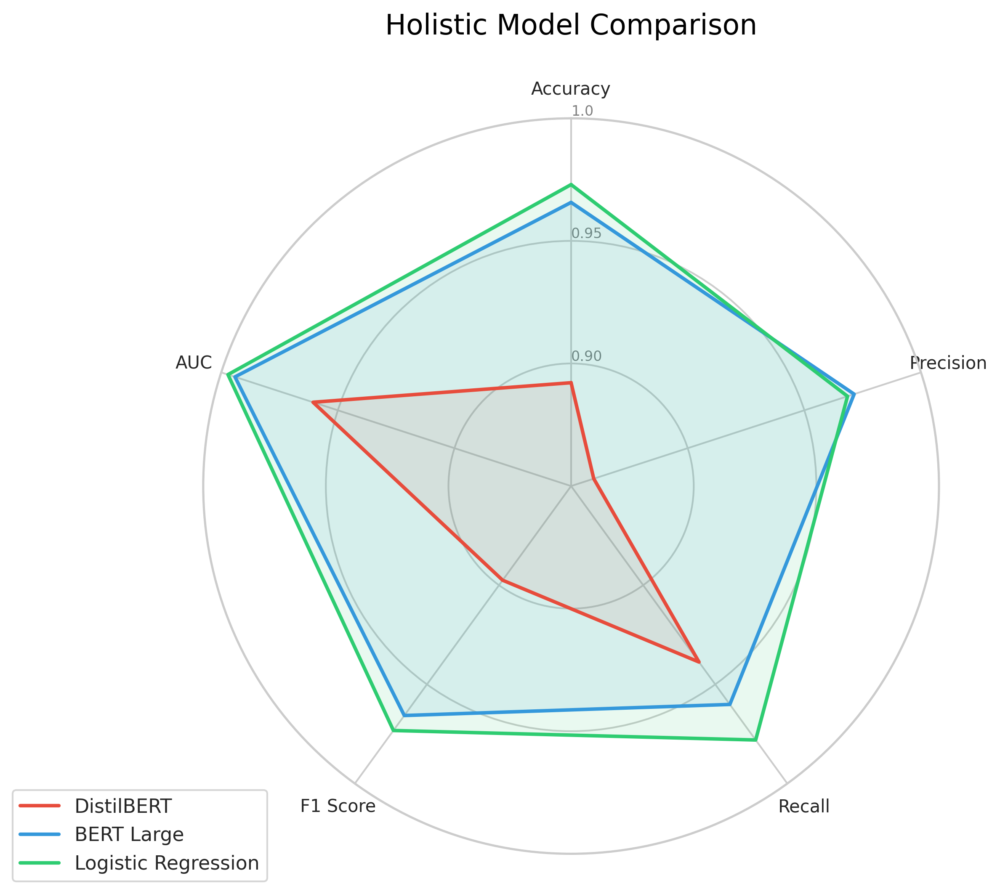


 All 3 plots saved successfully to: /content/gdrive/MyDrive/Data mining/text mining/data/visualization


In [ ]:
import sys
if "/content/AI-Gender-Stereotypes/src/visualization" not in sys.path:
    sys.path.append("/content/AI-Gender-Stereotypes/src/visualization")

import models_comparison
import importlib

importlib.reload(models_comparison)
models_comparison.main()

#Counterfactual Causal Probing

##Counterfactual Generation

In [10]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 22.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Sanity Check & Edge Cases Evaluation

In [12]:
CODE_PATH = "/content/AI-Gender-Stereotypes/src/counterfactual_causal_probing"

if CODE_PATH not in sys.path:
    sys.path.append(CODE_PATH)

import importlib
import counterfactual_generation
importlib.reload(counterfactual_generation)

extra_test_sentences = [
    "She is a machine learning engineer and her models are amazing.",
    "My wife asked ChatGPT to write her a cover letter.",
    "He fine-tuned the model himself, so the credit is his.",
    "I told him that his prompt was too long.",
    "Women in AI are underrepresented, but more girls are learning to code.",
    "My girlfriend thinks AI art is not real art.",
    "Mr. Altman and Ms. Murati spoke at the conference.",
    "Mrs. Smith teaches her students how to use Copilot.",
    "Miss Johnson said she will miss working with the data science team.",
    "My mom and dad both use AI chatbots to plan trips.",
    "The guys on my team think the gals in marketing use AI more.",
    "Her boyfriend built a GPT wrapper and sold it to his uncle.",
    "Ladies and gentlemen, welcome to the AI ethics panel.",
    "My daughters love talking to Alexa, but my sons prefer Siri.",
    "Yes sir, I will ask my grandma to try the new voice assistant.",
    "The queen of prompt engineering shared her tips with her followers.",
    "Is this laptop hers or his?",
    "Every female researcher I know has faced bias from male reviewers.",
    "My sister and her husband are both software developers.",
    "He said she was right about the transformer architecture.",
]

print("=" * 60)
print("Running Sanity Checks on Extra Test Sentences")
print("=" * 60)

for i, s in enumerate(extra_test_sentences, 1):
    flipped = counterfactual_generation.swap_gender(s)
    print(f"[{i:02d}] Original: {s}")
    print(f"     Flipped:  {flipped}\n")

print("=" * 60)
print("✅ Sanity check complete. Ready for full dataset processing.")
print("=" * 60)

Running Sanity Checks on Extra Test Sentences
[01] Original: She is a machine learning engineer and her models are amazing.
     Flipped:  He is a machine learning engineer and his models are amazing.

[02] Original: My wife asked ChatGPT to write her a cover letter.
     Flipped:  My husband asked ChatGPT to write him a cover letter.

[03] Original: He fine-tuned the model himself, so the credit is his.
     Flipped:  She fine-tuned the model herself, so the credit is hers.

[04] Original: I told him that his prompt was too long.
     Flipped:  I told her that her prompt was too long.

[05] Original: Women in AI are underrepresented, but more girls are learning to code.
     Flipped:  Men in AI are underrepresented, but more boys are learning to code.

[06] Original: My girlfriend thinks AI art is not real art.
     Flipped:  My boyfriend thinks AI art is not real art.

[07] Original: Mr. Altman and Ms. Murati spoke at the conference.
     Flipped:  Ms. Altman and Mr. Murati spoke at 

In [ ]:
import sys, importlib
CODE_PATH = "/content/AI-Gender-Stereotypes/src/counterfactual_causal_probing"
if CODE_PATH not in sys.path:
    sys.path.append(CODE_PATH)

import counterfactual_generation
importlib.reload(counterfactual_generation)

counterfactual_generation.main()

Loading original data from /content/gdrive/MyDrive/Data mining/text mining/data/processed/word2vec_posts.pkl ...
Loaded 56267 posts.
Texts with at least one gender word: 40276 / 56267 (71.6%)
  processed 5000/40276
  processed 10000/40276
  processed 15000/40276
  processed 20000/40276
  processed 25000/40276
  processed 30000/40276
  processed 35000/40276
  processed 40000/40276
Removed 171 rows with no change after swapping.
Final counterfactual pairs: 40105

--- n_swaps distribution ---
count    40105.000000
mean         3.597008
std          9.493009
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        354.000000
Name: n_swaps, dtype: float64

--- gender_context of swapped posts ---
gender_context
male      23714
female    13405
both       2195
none        791
Name: count, dtype: int64

--- 5 random examples ---
ORIGINAL: Queen Jemima on St. George's Day. Professor Jemima Stackridge, now believing herself to be channeling the ancient qu

###Grammatical Correction with LanguageTool

In [18]:
!pip install -q language_tool_python


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 3.1 MB/s eta 0:00:00


In [19]:
import sys, importlib
CODE_PATH = "/content/AI-Gender-Stereotypes/src/counterfactual_causal_probing"
if CODE_PATH not in sys.path:
    sys.path.append(CODE_PATH)

import grammar_validation
importlib.reload(grammar_validation)
grammar_validation.main()

Loading /content/gdrive/MyDrive/Data mining/text mining/data/counterfactual/counterfactual_posts.pkl ...
Loaded 40105 counterfactual pairs.
Running LanguageTool on changed sentences ...


  checked 1000/40105
  checked 2000/40105
  checked 3000/40105
  checked 4000/40105
  checked 5000/40105
  checked 6000/40105
  checked 7000/40105
  checked 8000/40105
  checked 9000/40105
  checked 10000/40105
  checked 11000/40105
  checked 12000/40105
  checked 13000/40105
  checked 14000/40105
  checked 15000/40105
  checked 16000/40105
  checked 17000/40105
  checked 18000/40105
  checked 19000/40105
  checked 20000/40105
  checked 21000/40105
  checked 22000/40105
  checked 23000/40105
  checked 24000/40105
  checked 25000/40105
  checked 26000/40105
  checked 27000/40105
  checked 28000/40105
  checked 29000/40105
  checked 30000/40105
  checked 31000/40105
  checked 32000/40105
  checked 33000/40105
  checked 34000/40105
  checked 35000/40105
  checked 36000/40105
  checked 37000/40105
  checked 38000/40105
  checked 39000/40105
  checked 40000/40105

Flagged pairs (at least one new error): 1406 / 40105 (3.5%)

--- Top 15 new error rules ---
MORFOLOGIK_RULE_EN_US               

Grammar Validation: Summary

We checked all 40,105 counterfactual pairs with LanguageTool. For each pair, we compared the original sentence with the swapped sentence and counted only errors that appear in the swapped version but not in the original. This way, mistakes that were already in the user's post are not counted.

**Result:** only 1,406 pairs (3.5%) were flagged with at least one new error. In 96.5% of the pairs, the gender swap did not create any new error.

The 3.5% is an upper bound. Most flags (1,134) come from the spelling checker (`MORFOLOGIK_RULE_EN_US`) and from rules that are not related to gender, such as lowercase "i", numbers written as digits, or "PhD". The gender words we swap in are correctly spelled, so these flags are probably not real errors caused by the swap. Only a few rule types could reflect real swap errors, such as "a" vs. "an" (44) and "your" vs. "you" (78).

We did not auto-correct the flagged texts. Auto-correction would also fix errors from the original post, so the original and the counterfactual would differ in more than gender.

manual review of a random 5% sample of the flagged pairs (71 pairs, 114 errors) to estimate how many of the flags are real errors.

In [25]:
# ===== Manual review of the LanguageTool flags =====
import pandas as pd
from IPython.display import display

REVIEW_PATH = "/content/gdrive/MyDrive/Data mining/text mining/data/counterfactual/manual_review_sample_suggested.csv"
review = pd.read_csv(REVIEW_PATH)

n_errors = len(review)
n_pairs = review["row_index"].nunique()
n_real = (review["is_real_error"] == "yes").sum()

print(f"Reviewed: {n_errors} flagged errors in {n_pairs} pairs")
print(f"Real errors caused by the swap: {n_real} / {n_errors} ({n_real / n_errors:.1%})")
print(f"False alarms: {n_errors - n_real} / {n_errors} ({(n_errors - n_real) / n_errors:.1%})")

# pairs with at least one real error
pairs_real = review.groupby("row_index")["is_real_error"].apply(lambda s: (s == "yes").any()).sum()
print(f"Pairs with at least one real error: {pairs_real} / {n_pairs} ({pairs_real / n_pairs:.1%})")

# what kind of errors
print("\n--- Errors by category ---")
summary = (review.groupby(["category", "is_real_error"]).size()
           .rename("count").reset_index()
           .sort_values("count", ascending=False))
display(summary)

# a few examples of each category
pd.set_option("display.max_colwidth", 120)
for cat, g in review.groupby("category"):
    print(f"\n=== {cat} ({len(g)}) ===")
    display(g[["rule_id", "original_sentence", "flipped_sentence", "notes"]].head(3))


Reviewed: 114 flagged errors in 71 pairs
Real errors caused by the swap: 97 / 114 (85.1%)
False alarms: 17 / 114 (14.9%)
Pairs with at least one real error: 55 / 71 (77.5%)

--- Errors by category ---


,category,is_real_error,count
1,bug_case_changed,yes,79
3,not_a_swap_error,no,17
2,bug_ms_to_mr,yes,14
0,bug_caps_lost,yes,4



=== bug_caps_lost (4) ===


,rule_id,original_sentence,flipped_sentence,notes
3,UPPERCASE_SENTENCE_START,HE SAID IT.,she SAID IT.,capital letters lost: HE -> she
100,CAPITALIZATION,HAPPY FATHER'S DAY!,HAPPY mother's DAY!,capital letters lost: FATHER'S -> mother's
107,UPPERCASE_SENTENCE_START,GUYS WE ARE HERE THIS IS SO UNREAL,gals WE ARE HERE THIS IS SO UNREAL,capital letters lost: GUYS -> gals



=== bug_case_changed (79) ===


,rule_id,original_sentence,flipped_sentence,notes
1,NUMBERS_IN_WORDS,[ UltraBabyVegeta: [ Nuka\_darkRum: [ KoalaOk3336: [ [ TraklGe: [ HuntAlternative: [ medy17: [ Frank6Will: [ DHPerry...,[ UltraBabyVegeta: [ Nuka\_darkRum: [ KoalaOk3336: [ [ TraklGe: [ HuntAlternative: [ medy17: [ Frank6will: [ DHPerry...,a non-gender word changed case: Frank6Will: -> Frank6will:
2,MORFOLOGIK_RULE_EN_US,"UPDATE: Gemini 3 was brought up during the Q&A in this event, and unfortunately i was not recording but something wa...","UPDATE: Gemini 3 was brought up during the Q&a in this event, and unfortunately i was not recording but something wa...",a non-gender word changed case: Q&A -> Q&a
6,MORFOLOGIK_RULE_EN_US,"Company: - CRM product - 2k employees - East Germany, medium size city - Above average salary and benefits - Two day...","Company: - CRM product - 2k employees - East Germany, medium size city - Above average salary and benefits - Two day...",a non-gender word changed case: Apex(Salesforce) -> Apex(salesforce)



=== bug_ms_to_mr (14) ===


,rule_id,original_sentence,flipped_sentence,notes
4,MORFOLOGIK_RULE_EN_US,"Long story short, I've graduated in september with the french equivalent of an MS in mechanical engineering.","Long story short, I've graduated in september with the french equivalent of an mr in mechanical engineering.",'MS' (degree / Microsoft) was swapped to 'mr': MS -> mr
5,EN_A_VS_AN,"Long story short, I've graduated in september with the french equivalent of an MS in mechanical engineering.","Long story short, I've graduated in september with the french equivalent of an mr in mechanical engineering.",'MS' (degree / Microsoft) was swapped to 'mr': MS -> mr
17,MORFOLOGIK_RULE_EN_US,"You guys are helping MS to put bars on Bing You guys do realize, that by posting images and text of how you bypassed...","You gals are helping mr to put bars on Bing You gals do realize, that by posting images and text of how you bypassed...",'MS' (degree / Microsoft) was swapped to 'mr': MS -> mr



=== not_a_swap_error (17) ===


,rule_id,original_sentence,flipped_sentence,notes
0,YOUR_YOU,"For an advice subreddit, you guys can be pretty nasty and unhelpful On my normal account, I frequently use this subr...","For an advice subreddit, you gals can be pretty nasty and unhelpful On my normal account, I frequently use this subr...",LanguageTool false positive: 'you gals' is correct
19,MORFOLOGIK_RULE_EN_US,Powerpuff Girls style image!,Powerpuff Boys style image!,"named entity (Powerpuff Girls), not a grammar error"
20,MORFOLOGIK_RULE_EN_US,"I asked GPT which Spice Girl they would be and Chat says ""Cardamom Spice."" Then I requested a cartoon ""Powerpuff gir...","I asked GPT which Spice Boy they would be and Chat says ""Cardamom Spice."" Then I requested a cartoon ""Powerpuff boys...","named entity (Spice Girls / Powerpuff Girls), not a grammar error"


The manual review of 114 flagged errors (71 pairs) showed that 85% of them were real errors, and all of them came from bugs in our swap code, not from the gender swap itself. The code changed the case of words it did not swap (e.g., "Q&A" → "Q&a", "U.S." → "U.s."), swapped "MS" (degree / Microsoft) to "mr", and lost capital letters ("GUYS" → "gals"). We fixed these bugs in `counterfactual_generation.py` and will re-run the generation and the grammar validation, so the final validation describes the corrected data.

###Stage 2 for counterfactual generation

In [27]:
import sys, importlib
CODE_PATH = "/content/AI-Gender-Stereotypes/src/counterfactual_causal_probing"
if CODE_PATH not in sys.path:
    sys.path.append(CODE_PATH)

import counterfactual_generation
importlib.reload(counterfactual_generation)

counterfactual_generation.main()

Loading original data from /content/gdrive/MyDrive/Data mining/text mining/data/processed/word2vec_posts.pkl ...
Loaded 56267 posts.
Texts with at least one gender word: 40276 / 56267 (71.6%)
  processed 5000/40276
  processed 10000/40276
  processed 15000/40276
  processed 20000/40276
  processed 25000/40276
  processed 30000/40276
  processed 35000/40276
  processed 40000/40276
Removed 210 rows with no change after swapping.
Final counterfactual pairs: 40066

--- n_swaps distribution ---
count    40066.000000
mean         3.590001
std          9.491341
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        354.000000
Name: n_swaps, dtype: float64

--- gender_context of swapped posts ---
gender_context
male      23714
female    13405
both       2195
none        752
Name: count, dtype: int64

--- 5 random examples ---
ORIGINAL: i would like some inputs on how to proceed with this program Hello guys I would like to have some guidance from the 

###Control Condition

In [28]:
import control_generation
importlib.reload(control_generation)
control_generation.main()

Loading /content/gdrive/MyDrive/Data mining/text mining/data/counterfactual/counterfactual_posts.pkl ...
Loaded 40066 counterfactual pairs.

Posts with a control version: 18186 / 40066 (45.4%)
Same number of swaps as the gender version: 64.5% of them

--- n_ctrl_swaps distribution ---
count    18186.000000
mean         2.358243
std          2.964876
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         59.000000
Name: n_ctrl_swaps, dtype: float64

--- 5 random examples ---
ORIGINAL: Claude Sonnet Pro For Programming and Bad Rate Limitations I'm strictly looking to create some network automation programs. Pretty involved, especially with the logic, you have to understand the engineering aspect to properly implement the code. Used ChatGPT gave me some network automation ideas it 
CONTROL:  Claude Sonnet Pro For Programming and Bad Rate Limitations I'm strictly looking to create some network automation programs. Pretty involved, especially wit

###grammar validation stage 2

In [35]:
import sys, importlib
CODE_PATH = "/content/AI-Gender-Stereotypes/src/counterfactual_causal_probing"
if CODE_PATH not in sys.path:
    sys.path.append(CODE_PATH)

import grammar_validation
importlib.reload(grammar_validation)
grammar_validation.main()

Loading /content/gdrive/MyDrive/Data mining/text mining/data/counterfactual/counterfactual_posts.pkl ...
Loaded 40066 counterfactual pairs.
Running LanguageTool on changed sentences ...
  checked 1000/40066
  checked 2000/40066
  checked 3000/40066
  checked 4000/40066
  checked 5000/40066
  checked 6000/40066
  checked 7000/40066
  checked 8000/40066
  checked 9000/40066
  checked 10000/40066
  checked 11000/40066
  checked 12000/40066
  checked 13000/40066
  checked 14000/40066
  checked 15000/40066
  checked 16000/40066
  checked 17000/40066
  checked 18000/40066
  checked 19000/40066
  checked 20000/40066
  checked 21000/40066
  checked 22000/40066
  checked 23000/40066
  checked 24000/40066
  checked 25000/40066
  checked 26000/40066
  checked 27000/40066
  checked 28000/40066
  checked 29000/40066
  checked 30000/40066
  checked 31000/40066
  checked 32000/40066
  checked 33000/40066
  checked 34000/40066
  checked 35000/40066
  checked 36000/40066
  checked 37000/40066
  checked

After fixing the case-handling bugs, LanguageTool flagged only 437 of 40,066 pairs (1.1%, down from 3.5%).

##Causal Probing Experiments

###Hard/Soft AI Classification

###Sentiment Scores

###Embedding Position

In [ ]:
%%bash
cd /content/AI-Gender-Stereotypes

# 1. מושכים עדכונים למקרה שקלוד עשה שינויים בגיט
git pull origin main

# 2. מאפסים כדי לוודא ששום קובץ דאטה לא מסומן בטעות
git reset

# 3. מוסיפים רק את הקובץ הספציפי שערכת (יש לשנות את הנתיב בהתאם לקובץ)
git add src/counterfactual_causal_probing/counterfactual_generation.py

# 4. בודקים שרק הקובץ הנכון סומן לירוק
git status

# 5. שומרים עם הודעה שמתארת את השינוי
git commit -m "Update file from Colab"

# 6. דוחפים את השינויים לגיט
git push origin main